# Stage 8 — Error analysis (8.1), interpretability (8.2), limitations (8.3)

* **8.1** is purely *descriptive* and uses the frozen test predictions in `models/test/` (nothing is refitted, nothing is changed).
* **8.2** uses **development data only** (1981–2019): for each of the 5 expanding CV folds the frozen model is refitted on the fold's
  training rows (same protocol as Stages 4/6) and explained on that fold's *validation* block (out-of-sample, 2005–2019).
* **8.3** collects the limitations with our numbers.
Helpers: `src/interpret.py`, `src/final_report.py`.

### Step 1 — Setup and the models analysed

**WHAT:** load test labels, test inputs (Feature Set B rows of the test days — inputs only), and the seed-mean test forecasts. Models:
baselines (seasonal + persistence, persistence, climatology), best linear (`logreg_l1`; `lasso` = best linear MAE on test),
best boosters (CatBoost, LightGBM, CatBoost Tweedie, hurdle), deep (TFT, TSMixer, TiDE).

**Look for:** 2,192 days, as in Stage 7.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import experiment as E, splits as S, metrics as M, final_eval as FE, final_report as FR, interpret as I

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
np.random.seed(0); warnings.filterwarnings("ignore")
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 50, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
te, y_cls, y_reg = FR.truth()
Xall, Yall = E.load("B"); Xte = Xall.loc[te]
rain_today = E.rain_today(te)
pc, tc = FR.seed_mean(*FR.load_predictions("cls")[:2]); pr, _ = FR.seed_mean(FR.load_predictions("reg")[0])
CLS = ["baseline:seasonal+persistence", "baseline:persistence", "logreg_l1", "lightgbm", "catboost", "deep:tft", "deep:tsmixer"]
REG = ["baseline:seasonal+persistence", "lasso", "catboost_tweedie", "lightgbm", "hurdle_catboost_log_msess", "deep:tide",
       "deep:tsmixer", "deep:tft"]
tdate = S.target_dates(te)
season = FR.season_of(te)
print(len(te), "test days |", {s: int((season == s).sum()) for s in FR.SEASONS})

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2192 test days | {'pre-monsoon': 552, 'monsoon': 732, 'post-monsoon': 366, 'winter': 542}


# Part 1 — Prompt 8.1: error analysis on 2020–2025

### Step 2 — Slice 1: month (and season)

**WHAT:** BSS (vs the frozen climatology), ROC-AUC and MAE / bias by target month for the selected models; heat-map figure.

**WHY:** a single annual score hides where skill is gained or lost. **Look for:** the monsoon months (Jun–Sep), where Stage 7 found
almost no gain over seasonal + persistence, vs the transition months.

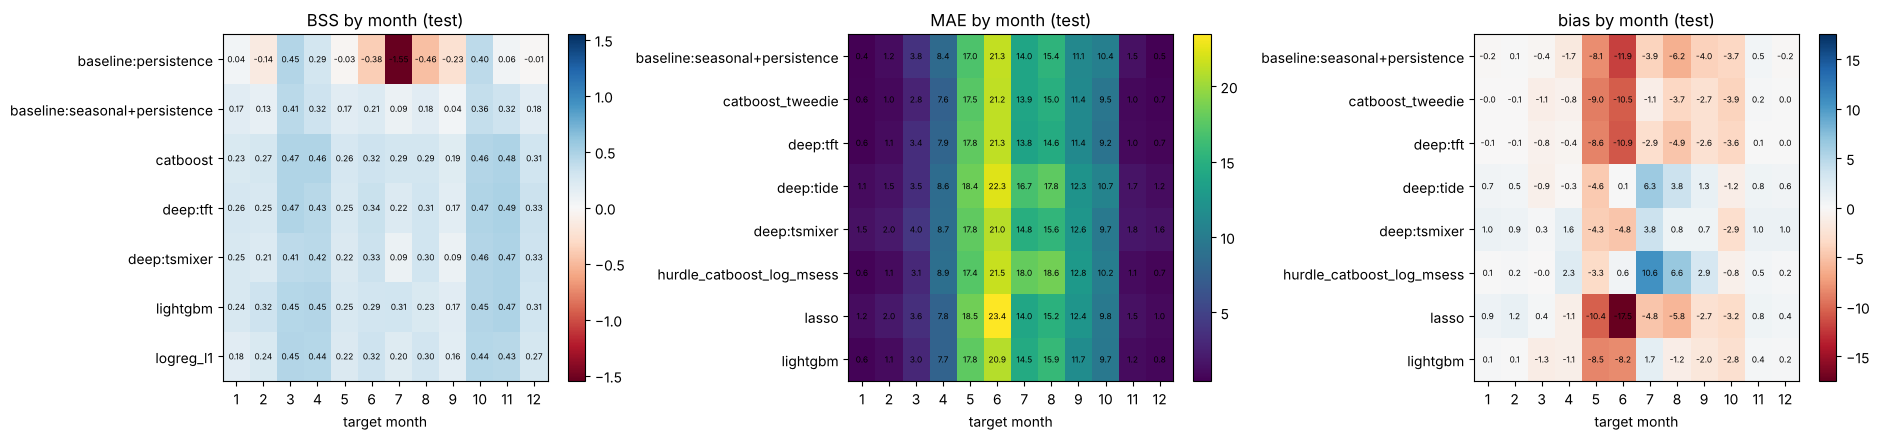

model,baseline:persistence,baseline:seasonal+persistence,catboost,deep:tft,deep:tsmixer,lightgbm,logreg_l1,wet_share
month,,,,,,,,
1,0.037,0.172,0.234,0.261,0.253,0.242,0.176,0.07
2,-0.143,0.132,0.274,0.246,0.208,0.315,0.237,0.11
3,0.454,0.412,0.467,0.470,0.406,0.446,0.455,0.32
4,0.289,0.319,0.460,0.431,0.417,0.453,0.438,0.76
5,-0.026,0.174,0.259,0.248,0.219,0.253,0.219,0.89
6,-0.376,0.212,0.316,0.339,0.327,0.292,0.320,0.97
7,-1.547,0.086,0.285,0.217,0.087,0.313,0.202,0.99
8,-0.463,0.179,0.287,0.310,0.303,0.234,0.301,0.97
9,-0.231,0.042,0.190,0.165,0.091,0.172,0.160,0.91


In [2]:
clim_c, clim_r = pc["baseline:climatology"], pr["baseline:climatology"]
rows = []
for mth in range(1, 13):
    k = (tdate.month == mth)
    for m in CLS:
        mm = M.classification_metrics(y_cls[k], pc[m][k], tc.get(m, 0.5), p_ref=clim_c[k])
        rows.append({"month": mth, "task": "cls", "model": m, "BSS": mm["BSS"], "ROC_AUC": mm["ROC_AUC"],
                     "wet_share": y_cls[k].mean()})
    for m in REG:
        mm = M.regression_metrics(y_reg[k], pr[m][k], y_ref=clim_r[k])
        rows.append({"month": mth, "task": "reg", "model": m, "MAE": mm["MAE"], "bias": mm["bias"], "MSESS": mm["MSESS"],
                     "obs_mean": y_reg[k].mean()})
bymonth = pd.DataFrame(rows); bymonth.to_csv(TAB / "08_errors_by_month.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, (task, met, cmap) in zip(axes, (("cls", "BSS", "RdBu"), ("reg", "MAE", "viridis"), ("reg", "bias", "RdBu"))):
    piv = bymonth[bymonth.task == task].pivot(index="model", columns="month", values=met)
    lim = np.nanmax(np.abs(piv.values)) if met != "MAE" else None
    im = ax.imshow(piv.values, aspect="auto", cmap=cmap, vmin=-lim if lim else None, vmax=lim)
    ax.set(yticks=range(len(piv)), yticklabels=piv.index, xticks=range(12), xticklabels=range(1, 13), xlabel="target month",
           title=f"{met} by month (test)"); plt.colorbar(im, ax=ax)
    for (i, j), v in np.ndenumerate(piv.values):
        ax.text(j, i, f"{v:.2f}" if met == "BSS" else f"{v:.1f}", ha="center", va="center", fontsize=6)
fig.tight_layout(); save(fig, "08_errors_by_month.png"); plt.show()
display(bymonth[bymonth.task == "cls"].pivot(index="month", columns="model", values="BSS").round(3).assign(
    wet_share=bymonth[(bymonth.task == "cls") & (bymonth.model == CLS[0])].set_index("month").wet_share.round(2)))

**Interpretation (by month, test years):**
- **The skill comes from the transition months.** BSS of the learners: March 0.41–0.47, April 0.42–0.46, October 0.44–0.47, November 0.43–0.49.
  In these months the wet-day share is 30–75 %, so tomorrow is genuinely uncertain, and humidity, temperature-range and pressure changes
  carry information beyond persistence.
- **Skill is lost in the monsoon.** July (wet share 0.99) and September give BSS 0.09–0.31 and 0.09–0.19. Almost every day is wet, so a
  probability near 1 is right by default and the remaining errors are rare dry breaks. TSMixer collapses there (0.087 / 0.091).
- **Winter** (wet share 5–11 %) sits at 0.21–0.33: a few rain days, mostly from western disturbances, partly anticipated.

**Meteorological reason:** occurrence predictability is highest where the climatological probability is intermediate and the local
moisture/stability state varies day to day (onset and withdrawal of the monsoon). Inside the active monsoon the uncertainty moves
from "whether" to "how much".

**Paper note:** *Test-period skill was concentrated in the pre- and post-monsoon transition months (BSS 0.41–0.49), whereas in the core
monsoon months, when rain fell on 91–99 % of days, BSS dropped to 0.09–0.34.*

### Step 3 — Slice 2: observed rainfall intensity bins

**WHAT:** for observed next-day rain in 0–<1, 1–<10, 10–<50 and ≥ 50 mm: mean observed vs mean forecast, bias, MAE and the ratio
forecast/observed (regression), and the mean P(wet) and POD (classification).

**WHY:** a skewed target is mostly dry/light days; averages hide the heavy-rain failure. **Look for:** how much of a ≥ 50 mm day is
forecast, and whether mean-type models (hurdle, TiDE, TSMixer) shrink less than MAE-type ones (Tweedie, LightGBM).

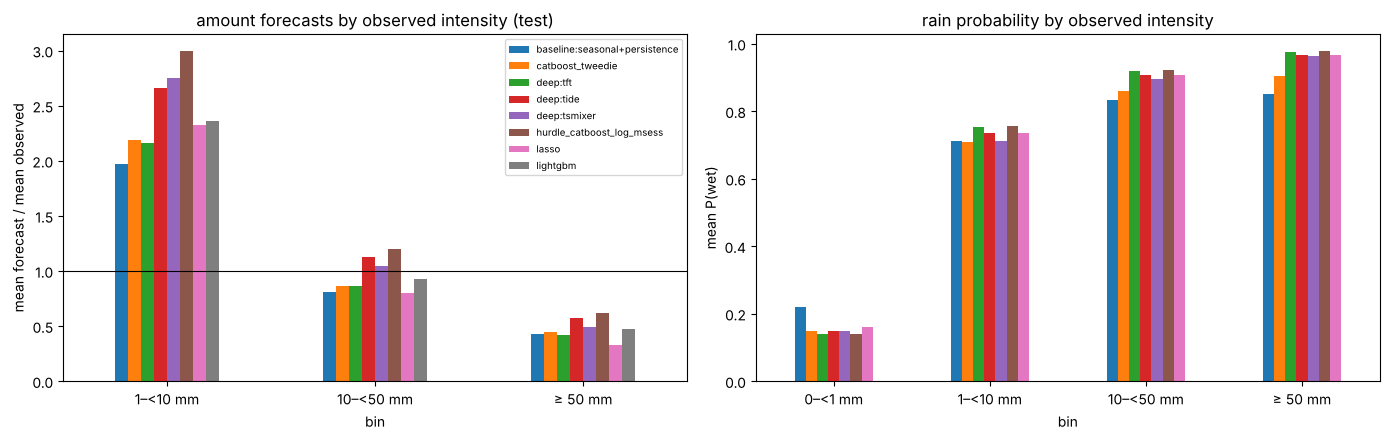

bin,0–<1 mm,10–<50 mm,1–<10 mm,≥ 50 mm
model,,,,
baseline:seasonal+persistence,24.37,0.81,1.97,0.43
catboost_tweedie,19.89,0.86,2.19,0.44
deep:tft,21.42,0.86,2.16,0.42
deep:tide,30.43,1.12,2.66,0.57
deep:tsmixer,40.48,1.04,2.75,0.49
hurdle_catboost_log_msess,27.68,1.20,3.00,0.62
lasso,29.89,0.80,2.32,0.32
lightgbm,22.62,0.93,2.36,0.47


bin,0–<1 mm,10–<50 mm,1–<10 mm,≥ 50 mm
model,,,,
baseline:seasonal+persistence,1.5,-4.6,4.9,-47.8
catboost_tweedie,1.2,-3.2,6.0,-46.3
deep:tft,1.3,-3.3,5.9,-48.7
deep:tide,1.9,2.9,8.4,-35.6
deep:tsmixer,2.6,1.0,8.9,-42.2
hurdle_catboost_log_msess,1.7,4.7,10.2,-31.7
lasso,1.9,-4.7,6.7,-56.4
lightgbm,1.4,-1.7,6.9,-44.1


bin,0–<1 mm,1–<10 mm,10–<50 mm,≥ 50 mm
model,,,,
baseline:persistence,0.219,0.711,0.832,0.850
baseline:seasonal+persistence,0.149,0.708,0.860,0.904
catboost,0.141,0.752,0.919,0.976
deep:tft,0.149,0.737,0.908,0.967
deep:tsmixer,0.148,0.713,0.895,0.964
lightgbm,0.141,0.756,0.923,0.978
logreg_l1,0.161,0.734,0.907,0.968


In [3]:
BINS = [(0, 1, "0–<1 mm"), (1, 10, "1–<10 mm"), (10, 50, "10–<50 mm"), (50, np.inf, "≥ 50 mm")]
rows = []
for lo, hi, lab in BINS:
    k = ((y_reg >= lo) & (y_reg < hi)).to_numpy()
    for m in REG:
        rows.append({"task": "reg", "bin": lab, "n_days": int(k.sum()), "model": m, "obs_mean": y_reg[k].mean(), "fc_mean": pr[m][k].mean(),
                     "bias": (pr[m][k] - y_reg[k]).mean(), "MAE": np.abs(pr[m][k] - y_reg[k]).mean(),
                     "ratio_fc_obs": pr[m][k].mean() / max(y_reg[k].mean(), 1e-9)})
    for m in CLS:
        rows.append({"task": "cls", "bin": lab, "n_days": int(k.sum()), "model": m, "mean_P_wet": pc[m][k].mean(),
                     "share_forecast_wet": (pc[m][k] >= tc.get(m, 0.5)).mean()})
bins = pd.DataFrame(rows); bins.to_csv(TAB / "08_errors_by_intensity.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
r = bins[bins.task == "reg"]
piv = r.pivot(index="bin", columns="model", values="ratio_fc_obs").loc[[b[2] for b in BINS]]
piv.drop(index="0–<1 mm").plot.bar(ax=axes[0], rot=0); axes[0].axhline(1, color="k", lw=0.8)
axes[0].set(ylabel="mean forecast / mean observed", title="amount forecasts by observed intensity (test)"); axes[0].legend(fontsize=7)
c = bins[bins.task == "cls"].pivot(index="bin", columns="model", values="mean_P_wet").loc[[b[2] for b in BINS]]
c.plot.bar(ax=axes[1], rot=0, legend=False); axes[1].set(ylabel="mean P(wet)", title="rain probability by observed intensity")
fig.tight_layout(); save(fig, "08_errors_by_intensity.png"); plt.show()
display(r.pivot(index="model", columns="bin", values="ratio_fc_obs").round(2))
display(r.pivot(index="model", columns="bin", values="bias").round(1))
display(c.T.round(3))

**Interpretation (by observed intensity):**
- **Dry and light days are over-forecast, heavy days are under-forecast.**
  - On 0–<1 mm days every model forecasts 1.2–2.6 mm (the "drizzle" of a conditional-mean forecast).
  - On 1–<10 mm days forecasts are 2–3 × too large.
  - On ≥ 50 mm days (167 days, mean 83 mm) forecasts reach only 32–62 % of the observed amount: bias −32 mm (hurdle) to −56 mm (Lasso).
- **Mean-type vs MAE-type models:**
  - The hurdle (0.62), TiDE (0.57) and TSMixer (0.49) shrink heavy days least, and they are the only models with a positive bias on
    10–<50 mm days (+1 to +4.7 mm).
  - The MAE-type Tweedie and LightGBM (0.44–0.47) and seasonal + persistence (0.43) shrink more. Lasso shrinks most (0.32).
  - So the mean-type models trade more drizzle on dry days for less damping of heavy days.
- **Occurrence is easy on heavy days:** mean P(wet) is 0.97–0.98 for the boosters on ≥ 50 mm days. The problem is the amount, not the
  occurrence.

**Meteorological reason:** heavy falls in Sylhet are driven by mesoscale convection and orographic lifting over the Meghalaya
plateau. A single cell's day-t surface state cannot resolve their timing and magnitude, so a loss-minimising model regresses towards
moderate values (Jensen/averaging effect).

**Paper note:** *All models forecast only 32–62 % of the observed amount on days with ≥ 50 mm, while over-forecasting dry days by
1–3 mm; mean-type formulations reduced, but did not remove, this damping.*

### Step 4 — Slice 3: year by year (2020–2025)

**WHAT:** per target year: observed total and wet-day share; BSS, MAE, bias and forecast total for the selected models.
ENSO context (NOAA CPC Oceanic Niño Index, approximate calendar-year labels — verify against the ONI table before citing):
2020–2022 La Niña (from mid-2020), 2023 El Niño (developing from mid-2023, ending spring 2024), late 2024–early 2025 weak La Niña,
2025 mostly neutral. Major Sylhet flood episodes were widely reported in June 2022 and June 2024.

**Look for:** whether skill/bias tracks wet vs dry years more than ENSO phase (six years cannot test ENSO effects).

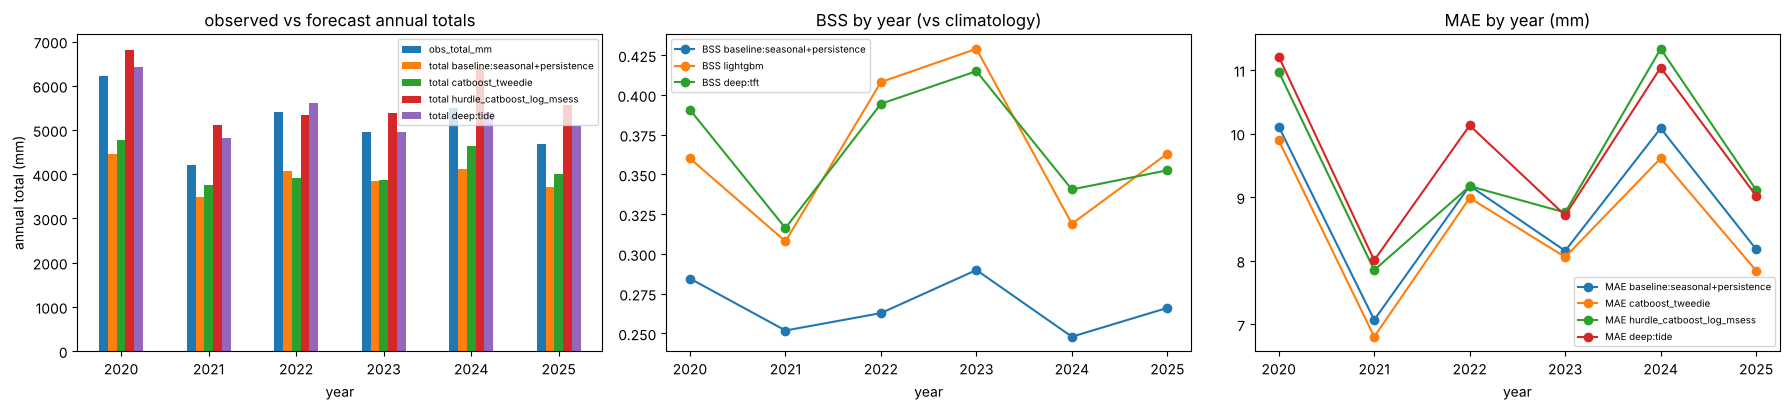

Spearman (obs total vs Tweedie MAE across years): 1.00


,ENSO (approx.),obs_total_mm,wet_share,max_day_mm,BSS baseline:seasonal+persistence,BSS lightgbm,BSS deep:tft,MAE baseline:seasonal+persistence,total baseline:seasonal+persistence,MAE catboost_tweedie,total catboost_tweedie,MAE hurdle_catboost_log_msess,total hurdle_catboost_log_msess,MAE deep:tide,total deep:tide
year,,,,,,,,,,,,,,,
2020,La Niña (from mid-year),6211.00,0.568,177.64,0.285,0.360,0.391,10.109,4455.211,9.893,4781.885,10.970,6818.440,11.210,6413.831
2021,La Niña,4211.08,0.548,106.51,0.252,0.308,0.316,7.069,3487.180,6.804,3755.457,7.852,5104.413,8.007,4811.802
2022,La Niña,5412.77,0.581,149.06,0.263,0.408,0.394,9.178,4068.310,8.987,3914.732,9.172,5340.376,10.127,5606.417
2023,El Niño (from mid-year),4943.30,0.532,185.91,0.290,0.429,0.415,8.155,3842.087,8.057,3860.531,8.758,5381.158,8.714,4950.528
2024,El Niño → neutral → weak La Niña,5503.38,0.566,202.35,0.248,0.319,0.341,10.082,4113.827,9.611,4646.635,11.331,6411.973,11.037,5414.964
2025,neutral (approx.),4686.83,0.545,192.09,0.266,0.363,0.353,8.181,3718.058,7.844,4005.458,9.113,5557.524,9.022,5089.884


In [4]:
ENSO = {2020: "La Niña (from mid-year)", 2021: "La Niña", 2022: "La Niña", 2023: "El Niño (from mid-year)",
        2024: "El Niño → neutral → weak La Niña", 2025: "neutral (approx.)"}
rows = []
for yr in range(2020, 2026):
    k = (tdate.year == yr)
    row = {"year": yr, "ENSO (approx.)": ENSO[yr], "obs_total_mm": y_reg[k].sum(), "wet_share": y_cls[k].mean(),
           "max_day_mm": y_reg[k].max()}
    for m in ("baseline:seasonal+persistence", "lightgbm", "deep:tft"):
        row[f"BSS {m}"] = M.classification_metrics(y_cls[k], pc[m][k], 0.5, p_ref=clim_c[k])["BSS"]
    for m in ("baseline:seasonal+persistence", "catboost_tweedie", "hurdle_catboost_log_msess", "deep:tide"):
        row[f"MAE {m}"] = np.abs(pr[m][k] - y_reg[k]).mean()
        row[f"total {m}"] = pr[m][k].sum()
    rows.append(row)
years = pd.DataFrame(rows).set_index("year"); years.to_csv(TAB / "08_errors_by_year.csv")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
years[["obs_total_mm"] + [c for c in years if c.startswith("total")]].plot.bar(ax=axes[0], rot=0)
axes[0].set(ylabel="annual total (mm)", title="observed vs forecast annual totals"); axes[0].legend(fontsize=7)
years[[c for c in years if c.startswith("BSS")]].plot(ax=axes[1], marker="o"); axes[1].set(title="BSS by year (vs climatology)")
years[[c for c in years if c.startswith("MAE")]].plot(ax=axes[2], marker="o"); axes[2].set(title="MAE by year (mm)")
for a in axes[1:]: a.legend(fontsize=7)
fig.tight_layout(); save(fig, "08_errors_by_year.png"); plt.show()
print("Spearman (obs total vs Tweedie MAE across years): %.2f" % years.obs_total_mm.corr(years["MAE catboost_tweedie"], method="spearman"))
years.round(3)

**Interpretation (by year):**
- Annual totals range from 4,211 mm (2021) to 6,211 mm (2020). **MAE scales with how wet the year is**: Spearman ρ = 1.00 between the
  observed total and Tweedie's MAE over the six years. MAE is 9.9 / 9.6 mm in the wettest years 2020 / 2024 and 6.8 mm in 2021.
- **BSS** varies less: LightGBM 0.31 (2021) to 0.43 (2023). Seasonal + persistence ranges 0.25–0.29.
- **Annual totals:**
  - The MAE-type Tweedie under-estimates every year by 11–28 %.
  - The hurdle is within −1 % to +21 % (over-estimating in five of six years), and TiDE is in between.
  - This is the bias trade-off seen in Stage 7, now year by year.
- **ENSO:** the three La Niña years (2020–2022) do not differ systematically from 2023 (El Niño developing) or 2024–2025 in skill or bias.
  With six years, one site and calendar-year labels, ENSO effects cannot be tested. The 2022 and 2024 flood years are not the worst for
  BSS (0.41 and 0.32), but 2024 has the second-highest MAE.

**Paper note:** *Year-to-year error tracked annual rainfall totals (Spearman ρ = 1.0 between total and MAE over 2020–2025), whereas no
systematic difference between ENSO phases could be identified in a six-year sample.*

### Step 5 — Slice 4: misses (FN) and false alarms (FP) — what weather precedes them?

**WHAT:** LightGBM seed-mean forecast at the mean frozen threshold → TP, FP, FN, TN. For each class: median of today's inputs
(rain, relative humidity, dew-point depression, specific humidity, pressure and its 1-day tendency, diurnal temperature range, wind,
days since rain), the season mix, and — for misses — the amount of rain that was missed.

**WHY:** "synoptic state" at a single grid cell can only be described by its surface variables; this shows which local states
confuse the model. **Look for:** misses on dry, low-humidity days with light rain; false alarms on humid, overcast days.

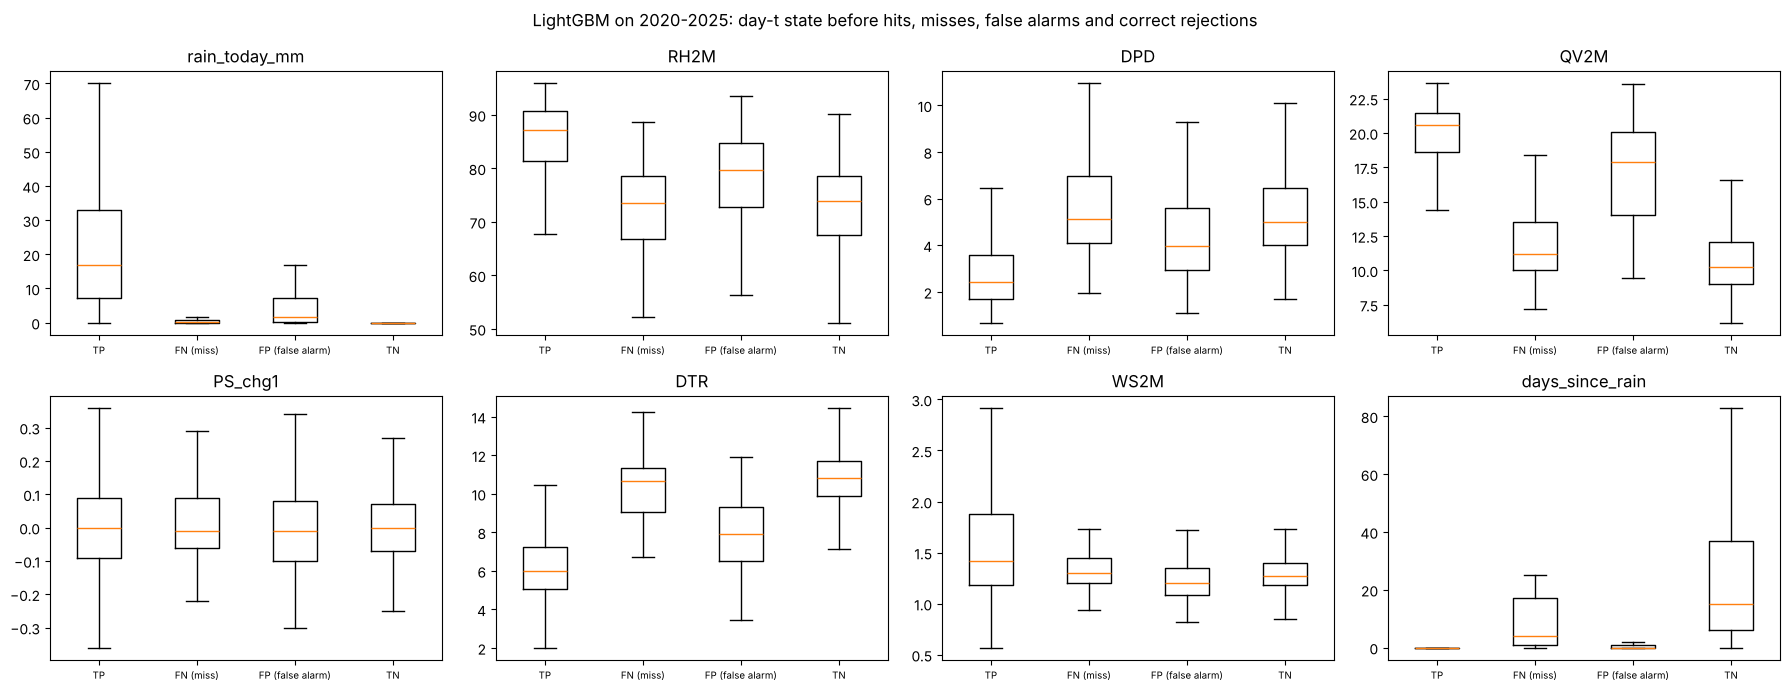

,n_days,rain_today_mm,RH2M,DPD,QV2M,PS,PS_chg1,DTR,WS2M,days_since_rain,rain_tomorrow_mm,P
outcome,,,,,,,,,,,,
TP,1163,16.84,87.07,2.42,20.61,99.29,0.00,5.98,1.42,0.0,17.18,0.96
FN,57,0.05,73.57,5.14,11.22,100.07,-0.01,10.66,1.30,4.0,2.78,0.15
FP,133,1.77,79.68,3.97,17.90,99.64,-0.01,7.92,1.20,0.0,0.14,0.64
TN,839,0.00,73.87,4.99,10.26,100.18,0.00,10.84,1.27,15.0,0.00,0.03


season,monsoon,post-monsoon,pre-monsoon,winter
outcome,,,,
TP,0.60,0.09,0.29,0.01
FN,0.02,0.19,0.33,0.46
FP,0.23,0.27,0.43,0.07
TN,0.00,0.26,0.16,0.59


rain on missed days (mm):
count    57.00
mean      4.84
std       6.34
min       1.01
50%       2.78
75%       5.09
90%       8.78
max      37.12
Name: rain_tomorrow_mm, dtype: float64


In [5]:
m = "lightgbm"
yhat = pc[m] >= tc[m]
cls = np.select([yhat & (y_cls == 1), yhat & (y_cls == 0), ~yhat & (y_cls == 1)], ["TP", "FP", "FN"], "TN")
VARS = ["rain_log1p", "RH2M", "DPD", "QV2M", "PS", "PS_chg1", "DTR", "WS2M", "days_since_rain"]
state = Xte[VARS].assign(rain_today_mm=rain_today.to_numpy(), outcome=cls, season=season.to_numpy(),
                         rain_tomorrow_mm=y_reg.to_numpy(), P=pc[m])
med = state.groupby("outcome")[["rain_today_mm"] + VARS[1:] + ["rain_tomorrow_mm", "P"]].median().loc[["TP", "FN", "FP", "TN"]]
med.insert(0, "n_days", state.outcome.value_counts())
seas = pd.crosstab(state.outcome, state.season, normalize="index").loc[["TP", "FN", "FP", "TN"]]
fn_amount = state[state.outcome == "FN"].rain_tomorrow_mm.describe(percentiles=[.5, .75, .9])
med.to_csv(TAB / "08_fn_fp_states.csv"); seas.to_csv(TAB / "08_fn_fp_season_mix.csv")
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, v in zip(axes.ravel(), ["rain_today_mm", "RH2M", "DPD", "QV2M", "PS_chg1", "DTR", "WS2M", "days_since_rain"]):
    data = [state.loc[state.outcome == o, v].to_numpy() for o in ("TP", "FN", "FP", "TN")]
    ax.boxplot(data, tick_labels=["TP", "FN (miss)", "FP (false alarm)", "TN"], showfliers=False)
    ax.set(title=v); ax.tick_params(axis="x", labelsize=7)
fig.suptitle("LightGBM on 2020-2025: day-t state before hits, misses, false alarms and correct rejections")
fig.tight_layout(); save(fig, "08_fn_fp_states.png"); plt.show()
display(med.round(2)); display(seas.round(2)); print("rain on missed days (mm):"); print(fn_amount.round(2))

**Interpretation (LightGBM, 2,192 days: 1,163 TP, 57 misses, 133 false alarms, 839 TN):**
- **Misses (FN) are light rain from a dry state:**
  - Median rain missed is 2.8 mm (75 % below 5.1 mm; max 37 mm).
  - Today is dry (median 0.05 mm, 4 days since rain), with low humidity (RH 73.6 %, dew-point depression 5.1 K, specific humidity
    11.2 g/kg) and a large diurnal range (10.7 K).
  - They occur in winter (46 %) and pre-monsoon (33 %).
  - Their state is almost identical to the correct dry forecasts (TN: RH 73.9 %, DPD 5.0 K, DTR 10.8 K). From the local surface state these
    days are **indistinguishable** from dry days: the rain comes from systems that arrive from outside the cell (western disturbances,
    pre-monsoon squall lines / nor'westers).
- **False alarms (FP) are humid days, often after rain:**
  - Median rain today is 1.8 mm, with RH 79.7 %, DPD 4.0 K, specific humidity 17.9 g/kg and DTR 7.9 K, between the TP and TN states.
  - They occur mostly pre-monsoon (43 %), post-monsoon (27 %) and monsoon (23 %).
  - The model is persuaded by moisture and persistence, but the trigger (convergence, instability) is absent.
- **Pressure tendency** barely separates the classes (medians ≈ 0) at a daily, single-cell resolution.

**Paper note:** *Missed rain days were predominantly light (median 2.8 mm) winter and pre-monsoon events preceded by a dry,
low-humidity local state indistinguishable from correct dry forecasts, whereas false alarms followed humid days with some rain.*

### Step 6 — Slice 5: state transitions — skill where persistence is always wrong

**WHAT:** split the test days by today's state (rain today ≥ 1 mm or not). Within **dry-today** days the event is "wet tomorrow"
(dry→wet onset); within **wet-today** days it is "dry tomorrow" (wet→dry cessation). Persistence is wrong on every transition by
definition. Report: base rate, ROC-AUC within the subset (pure discrimination of the transition), Brier skill vs seasonal + persistence,
hit rate on onsets / correct dry calls on cessations at the frozen thresholds.

**Look for:** whether the learners anticipate onsets and cessations, or only copy today's state.

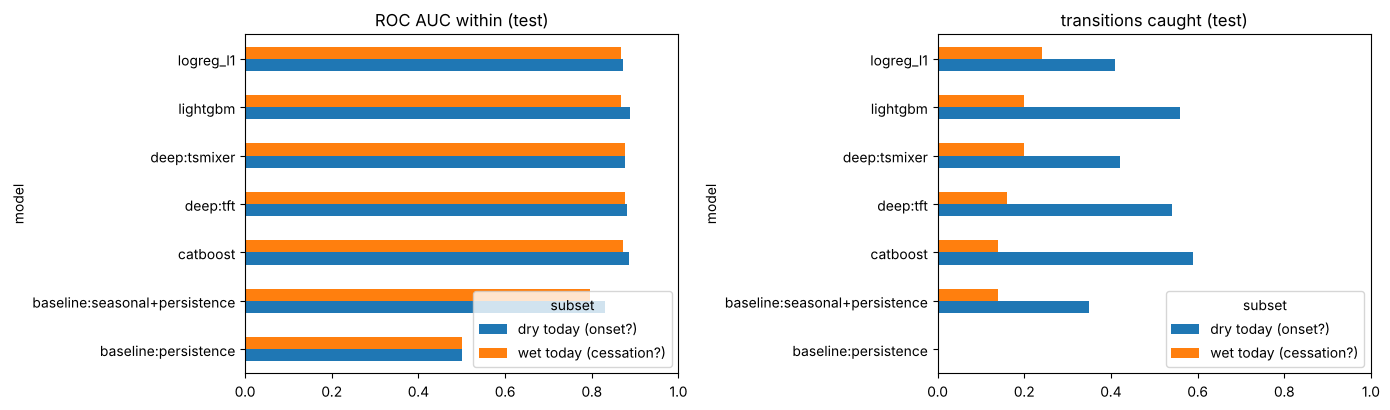

,subset,model,n_days,transitions,transition_rate,ROC_AUC_within,Brier,BSS_vs_seas_pers,transitions_caught,mean_P_event_on_transitions
0,dry today (onset?),baseline:seasonal+persistence,972,100,0.103,0.830,0.071,0.000,0.35,0.282
1,dry today (onset?),baseline:persistence,972,100,0.103,0.500,0.094,-0.330,0.00,0.146
2,dry today (onset?),logreg_l1,972,100,0.103,0.872,0.066,0.068,0.41,0.365
3,dry today (onset?),lightgbm,972,100,0.103,0.889,0.064,0.091,0.56,0.423
4,dry today (onset?),catboost,972,100,0.103,0.886,0.064,0.100,0.59,0.403
5,dry today (onset?),deep:tft,972,100,0.103,0.881,0.064,0.096,0.54,0.377
6,dry today (onset?),deep:tsmixer,972,100,0.103,0.876,0.067,0.050,0.42,0.358
7,wet today (cessation?),baseline:seasonal+persistence,1220,100,0.082,0.796,0.074,0.000,0.14,0.326
8,wet today (cessation?),baseline:persistence,1220,100,0.082,0.500,0.080,-0.081,0.00,0.150
9,wet today (cessation?),logreg_l1,1220,100,0.082,0.868,0.063,0.146,0.24,0.358


In [6]:
rows = []
for state_lab, today_wet in (("dry today (onset?)", False), ("wet today (cessation?)", True)):
    k = ((rain_today >= 1.0).to_numpy() == today_wet)
    event = y_cls[k].to_numpy() if not today_wet else 1 - y_cls[k].to_numpy()       # onset: wet tomorrow; cessation: dry tomorrow
    for mdl in CLS:
        p = pc[mdl][k]
        pe = p if not today_wet else 1 - p
        ref = pc["baseline:seasonal+persistence"][k]; refe = ref if not today_wet else 1 - ref
        hit = ((p >= tc.get(mdl, 0.5)) == (not today_wet))[event == 1].mean()
        rows.append({"subset": state_lab, "model": mdl, "n_days": int(k.sum()), "transitions": int(event.sum()),
                     "transition_rate": event.mean(), "ROC_AUC_within": roc_auc_score(event, pe),
                     "Brier": np.mean((pe - event) ** 2),
                     "BSS_vs_seas_pers": 1 - np.mean((pe - event) ** 2) / np.mean((refe - event) ** 2),
                     "transitions_caught": hit, "mean_P_event_on_transitions": pe[event == 1].mean()})
trans = pd.DataFrame(rows); trans.to_csv(TAB / "08_transitions.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, met in zip(axes, ("ROC_AUC_within", "transitions_caught")):
    trans.pivot(index="model", columns="subset", values=met).plot.barh(ax=ax)
    ax.set(title=met.replace("_", " ") + " (test)", xlim=(0, 1))
fig.tight_layout(); save(fig, "08_transitions.png"); plt.show()
trans.round(3)

**Interpretation (state transitions, where persistence is 100 % wrong):**
- **Onsets (dry today → wet tomorrow; 100 of 972 dry days):**
  - The learners discriminate well (ROC-AUC 0.87–0.89 vs 0.83 for seasonal + persistence) and catch **41–59 %** of onsets at their
    frozen thresholds (CatBoost 59 %, LightGBM 56 %, TFT 54 %), vs 35 % for seasonal + persistence and 0 % for persistence.
  - BSS vs seasonal + persistence on this subset: +0.05 to +0.10.
- **Cessations (wet today → dry tomorrow; 100 of 1,220 wet days):**
  - Discrimination is also good (AUC 0.87–0.88 vs 0.80), and the Brier skill gain over seasonal + persistence is even larger (+0.14 to +0.18).
  - But only **14–24 %** of cessations are called correctly at the threshold. After a wet day the models rarely dare to forecast "dry".
- So the models **do more than copy persistence**: their probabilities rise before onsets and fall before cessations. But the
  thresholded yes/no forecasts still follow today's state most of the time.

**Meteorological reason:** onsets in the transition seasons are preceded by moisture build-up (rising specific humidity, falling DTR),
which the models detect. Cessations depend on drying air arriving from outside the cell, which is less visible locally.

**Paper note:** *On transition days, where persistence is always wrong, the learners retained high discrimination (ROC-AUC 0.87–0.89)
and detected 41–59 % of rain onsets, but only 14–24 % of rain cessations.*

### Step 7 — Slice 6: calibration by season

**WHAT:** reliability curves (10 bins) per season for seasonal + persistence, `logreg_l1`, LightGBM and TFT; ECE, mean forecast
probability and observed frequency per season.

**WHY:** a forecast that is calibrated over the year can still be biased within each season. **Look for:** under-forecasting in
the (wetter) test monsoon and transition seasons; the usable probability range per season (monsoon probabilities cluster near 1).

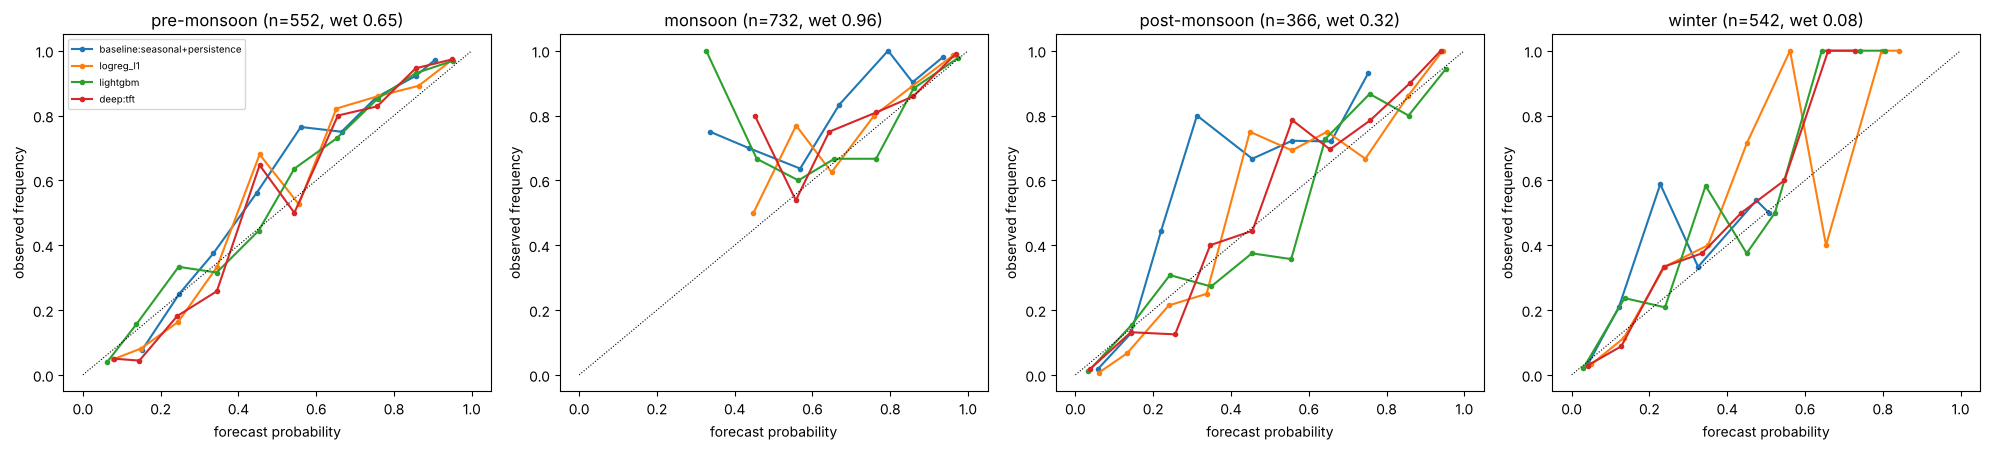

season,monsoon,post-monsoon,pre-monsoon,winter
model,,,,
baseline:seasonal+persistence,0.052,0.083,0.072,0.023
deep:tft,0.025,0.039,0.072,0.021
lightgbm,0.009,0.040,0.044,0.027
logreg_l1,0.029,0.062,0.059,0.028


model,baseline:seasonal+persistence,deep:tft,lightgbm,logreg_l1,observed
season,,,,,
monsoon,0.906,0.934,0.953,0.930,0.958
post-monsoon,0.276,0.311,0.336,0.335,0.317
pre-monsoon,0.610,0.633,0.619,0.633,0.654
winter,0.067,0.081,0.071,0.088,0.077


In [7]:
SEL = ["baseline:seasonal+persistence", "logreg_l1", "lightgbm", "deep:tft"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
rows = []
for ax, s in zip(axes, FR.SEASONS):
    k = (season == s).to_numpy()
    for mdl in SEL:
        cal = M.calibration(y_cls[k], pc[mdl][k])
        ax.plot(cal.mean_predicted, cal.observed_frequency, marker="o", ms=3, label=mdl)
        rows.append({"season": s, "model": mdl, "ECE": M.ece(y_cls[k], pc[mdl][k]), "mean_forecast": pc[mdl][k].mean(),
                     "observed_frequency": y_cls[k].mean(), "n_days": int(k.sum())})
    ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set(title=f"{s} (n={int(k.sum())}, wet {y_cls[k].mean():.2f})",
                                                  xlabel="forecast probability", ylabel="observed frequency")
axes[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "08_calibration_by_season.png"); plt.show()
calib = pd.DataFrame(rows); calib.to_csv(TAB / "08_calibration_by_season.csv", index=False)
display(calib.pivot(index="model", columns="season", values="ECE").round(3))
calib.pivot(index="model", columns="season", values="mean_forecast").round(3).T.assign(
    observed=calib.groupby("season").observed_frequency.first().round(3))

**Interpretation (calibration by season):**
- **Pre-monsoon and post-monsoon:** reliable, mostly within ±0.1 of the diagonal. ECE: LightGBM 0.044 / 0.040, TFT 0.072 / 0.039, seasonal +
  persistence 0.072 / 0.083. Mean forecast vs observed: pre-monsoon 0.61–0.63 vs 0.65, post-monsoon 0.31–0.34 vs 0.32.
- **Monsoon:** forecasts cluster at 0.85–1.0. The mean is 0.93–0.95 vs 0.958 observed (slight under-forecasting), and LightGBM's ECE is very
  low (0.009). The few forecasts below 0.7 are unreliable, but there are very few of them (curves built on handfuls of days).
- **Winter:** reliable at low probabilities (most days < 0.2). Above 0.5 the bins contain only a few days and observed frequencies jump
  (often *higher* than forecast).
- Probabilities are trustworthy in the transition seasons. In the monsoon and winter they are dominated by the seasonal base rate, and
  the informative range is narrow.

**Paper note:** *Rain-occurrence probabilities were well calibrated in the transition seasons (ECE ≈ 0.04 for LightGBM), whereas in
the monsoon and winter the forecasts concentrated near the seasonal base rate and the informative probability range was narrow.*

# Part 2 — Prompt 8.2: interpretability (development data only)

### Step 8 — Per-fold development models and grouped permutation importance

**WHAT:** for LightGBM (classification, seeds 0–4), CatBoost Tweedie (regression, seeds 0–4), `logreg_l1` and `lasso` (seed 0): refit
the frozen configuration on each fold's training rows and permute, on that fold's **validation** block (2005–2019), (a) each
engineering **family** (lags, rolling statistics, spell memory, season, tendencies, derived, current values), (b) each **physical
variable group** (rain memory, moisture, pressure, wind, temperature, season) jointly, and (c) each single column; 5 repeats.
Importance = increase of the Brier score (classification) or MAE (regression); mean ± std over folds × seeds.

**WHY joint permutation:** our 115 columns are strongly collinear (e.g. 5 lags and 4 rolling means of the same variable). Permuting one
column leaves its near-copies intact, so single-column importances understate shared information and are unstable; permuting the
whole group removes it. *Alternatives:* drop-column importance (needs refits — done as the Stage-6 family ablation), impurity
importance (biased towards high-cardinality features), SHAP (Step 9).

**Look for:** rain memory and moisture on top; stability across folds/seeds.

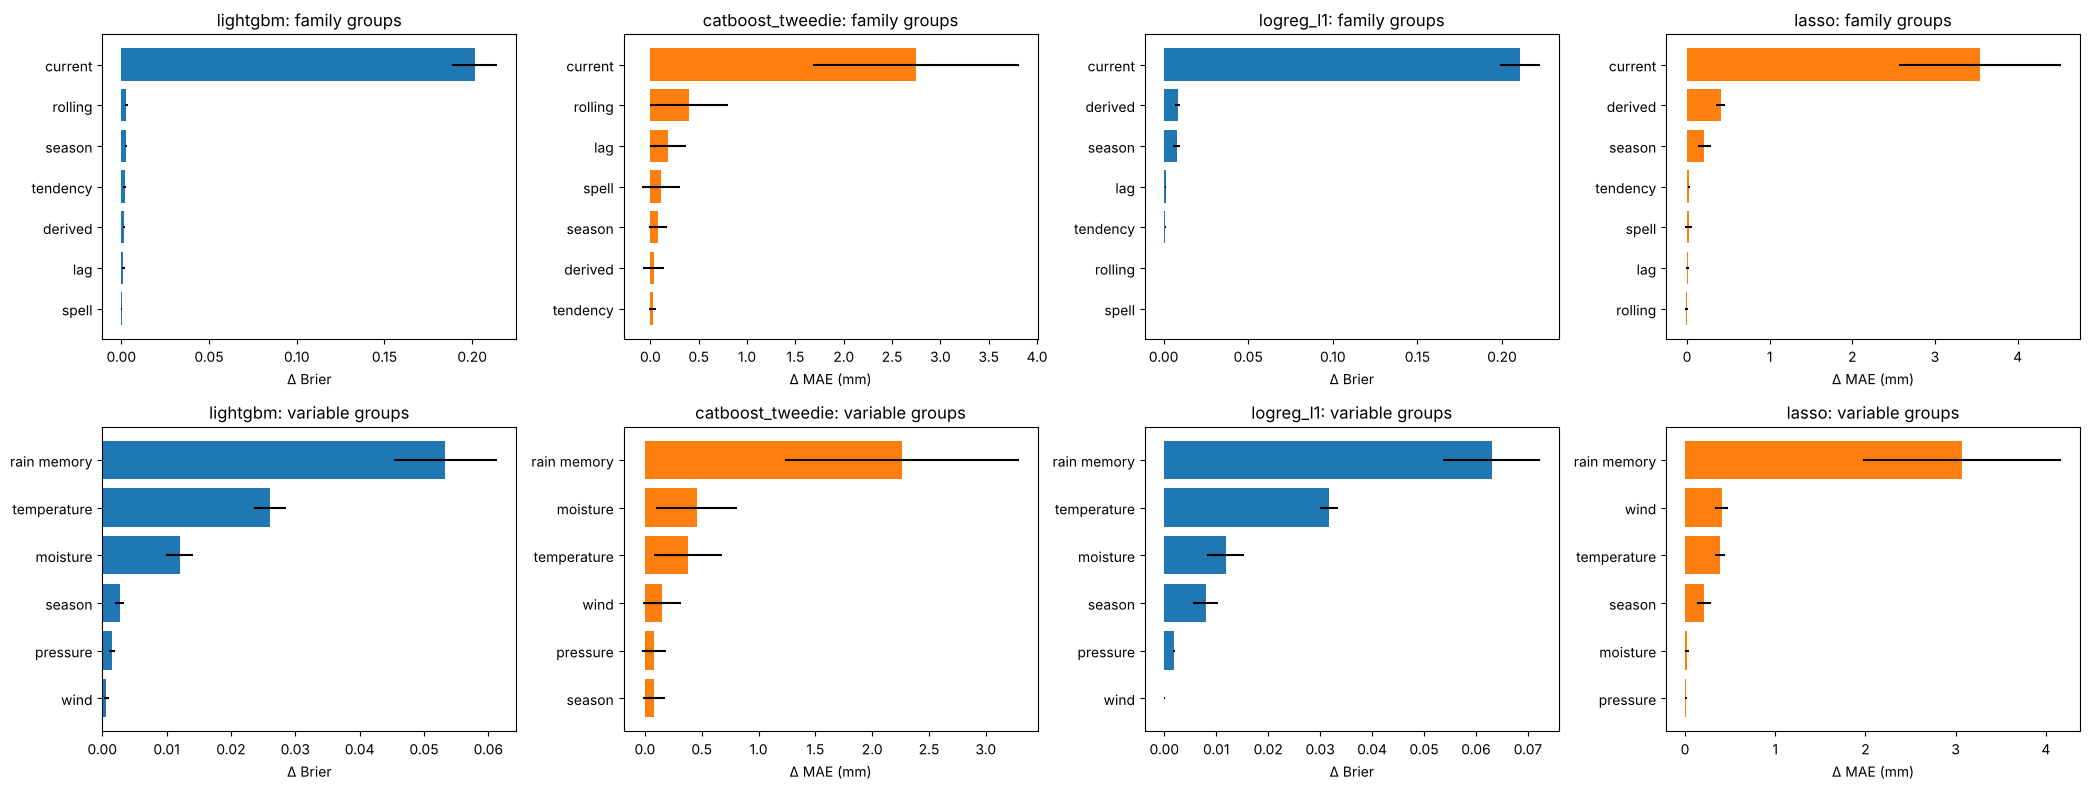

,model,kind,group,mean,std,relative_increase
115,catboost_tweedie,family,current,2.746e+00,1.064e+00,3.880e-01
118,catboost_tweedie,family,rolling,4.015e-01,4.029e-01,5.100e-02
117,catboost_tweedie,family,lag,1.823e-01,1.817e-01,2.480e-02
120,catboost_tweedie,family,spell,1.120e-01,1.955e-01,1.310e-02
119,catboost_tweedie,family,season,8.060e-02,9.540e-02,1.010e-02
116,catboost_tweedie,family,derived,3.360e-02,1.074e-01,2.900e-03
121,catboost_tweedie,family,tendency,2.180e-02,4.020e-02,2.400e-03
124,catboost_tweedie,variable,rain memory,2.261e+00,1.028e+00,3.146e-01
122,catboost_tweedie,variable,moisture,4.550e-01,3.592e-01,6.010e-02
126,catboost_tweedie,variable,temperature,3.770e-01,3.003e-01,4.960e-02


,model,kind,group,mean,std,relative_increase
231,lasso,column,rain_log1p,3.344e+00,1.153e+00,4.544e-01
103,catboost_tweedie,column,rain_log1p,1.172e+00,7.843e-01,1.571e-01
215,lasso,column,WS2M,4.669e-01,9.050e-02,6.510e-02
129,lasso,column,DTR,4.033e-01,4.080e-02,5.710e-02
226,lasso,column,doy_cos1,1.992e-01,6.970e-02,2.760e-02
114,catboost_tweedie,column,wet_today,1.990e-01,2.619e-01,2.390e-02
87,catboost_tweedie,column,WS2M,5.920e-02,1.393e-01,5.900e-03
487,logreg_l1,column,rain_log1p,3.990e-02,1.040e-02,5.254e-01
97,catboost_tweedie,column,days_since_rain,3.950e-02,8.620e-02,4.800e-03
113,catboost_tweedie,column,wet_run_len,3.910e-02,1.237e-01,3.500e-03


In [8]:
Xd, Yd = I.development()
folds = S.cv_folds(Xd.index)
SPECS = [("cls", "lightgbm", [0, 1, 2, 3, 4]), ("reg", "catboost_tweedie", [0, 1, 2, 3, 4]), ("cls", "logreg_l1", [0]), ("reg", "lasso", [0])]
fam_g, var_g = I.groups(Xd.columns, "family"), I.groups(Xd.columns, "variable")
col_g = {c: [c] for c in Xd.columns}
perm, models5 = [], {}
for task, name, seeds in SPECS:
    y = Yd[E.TARGET[task]]
    for k, (tr, va) in enumerate(folds, 1):
        for s in seeds:
            est = I.fold_model(task, name, s, Xd, y, tr)
            if k == 5:
                models5[(name, s)] = est
            for kind, g in (("family", fam_g), ("variable", var_g), ("column", col_g)):
                r = I.permutation_importance(est, Xd.loc[va], y[va], task, g, n_repeats=5 if kind != "column" else 3, seed=s)
                perm.append(r.assign(task=task, model=name, fold=k, seed=s, kind=kind))
perm = pd.concat(perm, ignore_index=True)
perm.to_csv(TAB / "08_permutation_importance_raw.csv", index=False)
agg = (perm.groupby(["model", "kind", "group", "fold", "seed"]).delta_loss.mean()
           .groupby(["model", "kind", "group"]).agg(["mean", "std"]).reset_index())
rel = perm.groupby(["model", "kind", "group"]).apply(lambda d: (d.delta_loss / d.base_loss).mean(), include_groups=False)
agg["relative_increase"] = rel.reindex(pd.MultiIndex.from_frame(agg[["model", "kind", "group"]])).to_numpy()
agg.to_csv(TAB / "08_permutation_importance.csv", index=False)
fig, axes = plt.subplots(2, 4, figsize=(21, 8))
for j, (task, name, _) in enumerate(SPECS):
    for i, kind in enumerate(("family", "variable")):
        a = agg[(agg.model == name) & (agg.kind == kind)].sort_values("mean")
        axes[i, j].barh(a.group, a["mean"], xerr=a["std"], color="tab:blue" if task == "cls" else "tab:orange")
        axes[i, j].set(title=f"{name}: {kind} groups", xlabel="Δ Brier" if task == "cls" else "Δ MAE (mm)")
fig.tight_layout(); save(fig, "08_permutation_importance_groups.png"); plt.show()
top = agg[agg.kind == "column"].sort_values("mean", ascending=False).groupby("model").head(10)
display(agg[agg.kind != "column"].sort_values(["model", "kind", "mean"], ascending=[True, True, False]).round(4))
display(top.round(4))

**Interpretation (grouped permutation on the 2005–2019 validation blocks; mean ± std over 5 folds × seeds):**
- **LightGBM (ΔBrier):**
  - Permuting the **current-day family** (today's values of all variables) raises the Brier score by 0.20 (+265 %). Every other family
    adds at most 0.003 when permuted alone, because lags and rolling statistics are redundant copies of the same information (consistent
    with the Stage-6 drop-family ablation).
  - By physical group: **rain memory 0.053 ± 0.008**, **temperature 0.026** (DTR, T2M_MIN), **moisture 0.012**, season 0.003, pressure
    0.0015, wind 0.0006.
- **logreg_l1** has the same ordering (rain memory 0.063, temperature 0.032, moisture 0.012).
- **CatBoost Tweedie (ΔMAE):** rain memory 2.26 mm, moisture 0.46, temperature 0.38, wind 0.15, pressure 0.08, season 0.08.
- **Lasso:** rain memory 3.1 mm, then **wind 0.41** and temperature 0.39 (DTR); moisture ≈ 0. The linear model uses wind speed as the
  proxy for the monsoon flow that other models take from humidity.
- **Single columns:** `rain_log1p` dominates everywhere. The rest are small and unstable (std often larger than the mean for Tweedie),
  which is the collinearity effect.

**Paper note:** *Grouped permutation importance on out-of-sample development folds attributed most skill to same-day rainfall
memory, followed by temperature-range and humidity variables; lagged and rolling features were individually redundant.*

### Step 9 — SHAP values for the best boosters (fold-5 models explained on 2017–2019 validation rows)

**WHAT:** `shap.TreeExplainer` on the fold-5 LightGBM classifier (seed 0; SHAP in log-odds) and the fold-5 CatBoost Tweedie regressor
(seed 0; SHAP in the log-link space), explained on the 1,095 fold-5 validation days (2017–2019, development). Beeswarm summary,
mean |SHAP| bar chart (also summed by physical group), and dependence plots for `rain_log1p`, `RH2M`, `DPD`, `PS_chg1`, `DTR`
and `doy_cos1`.

**WHY:** SHAP decomposes each single forecast into additive contributions (local explanations); its average |value| is a global
importance that, unlike permutation, never evaluates the model on impossible feature combinations. *Caveat:* with correlated features
TreeExplainer's attribution between near-duplicates is arbitrary — read groups, not single columns.

**Look for:** the shape of the main effects (monotone humidity effect, rain-today saturation, seasonal modulation).

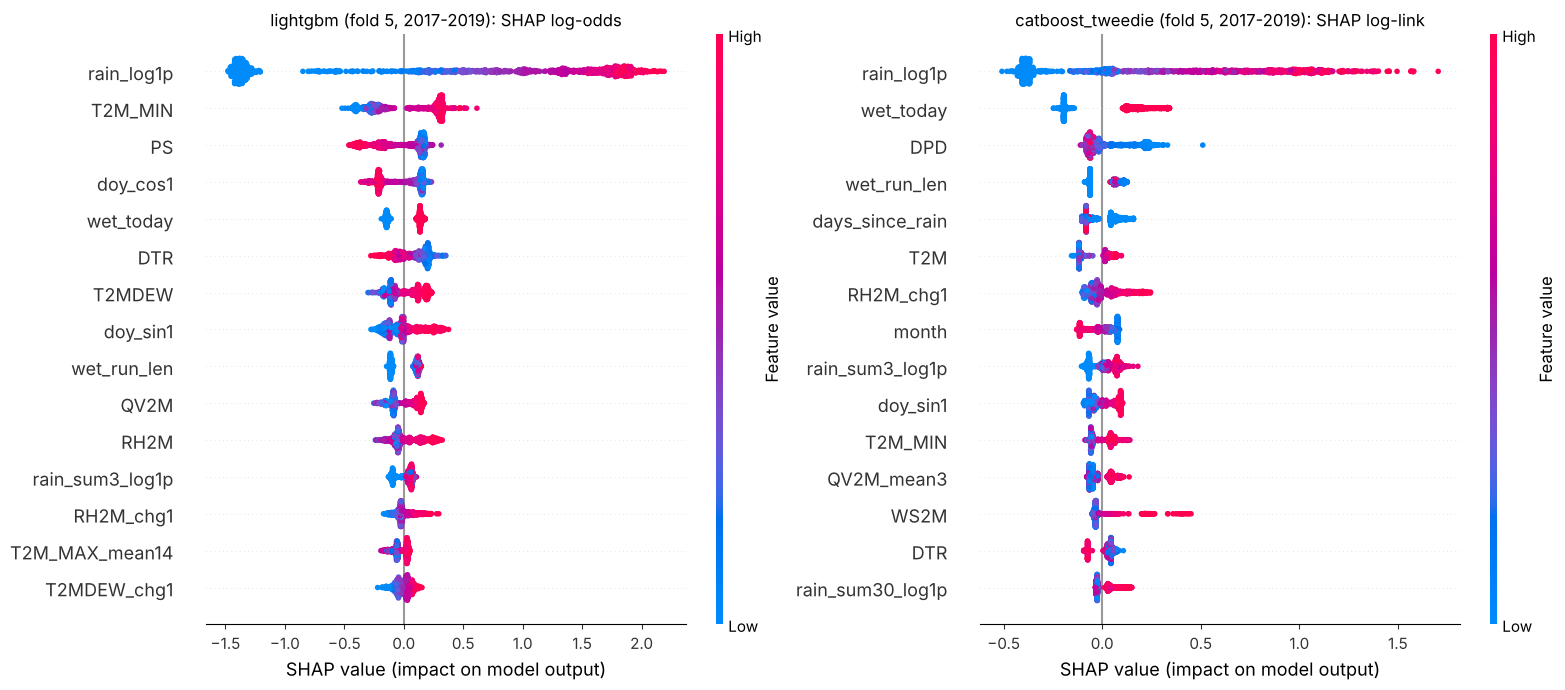

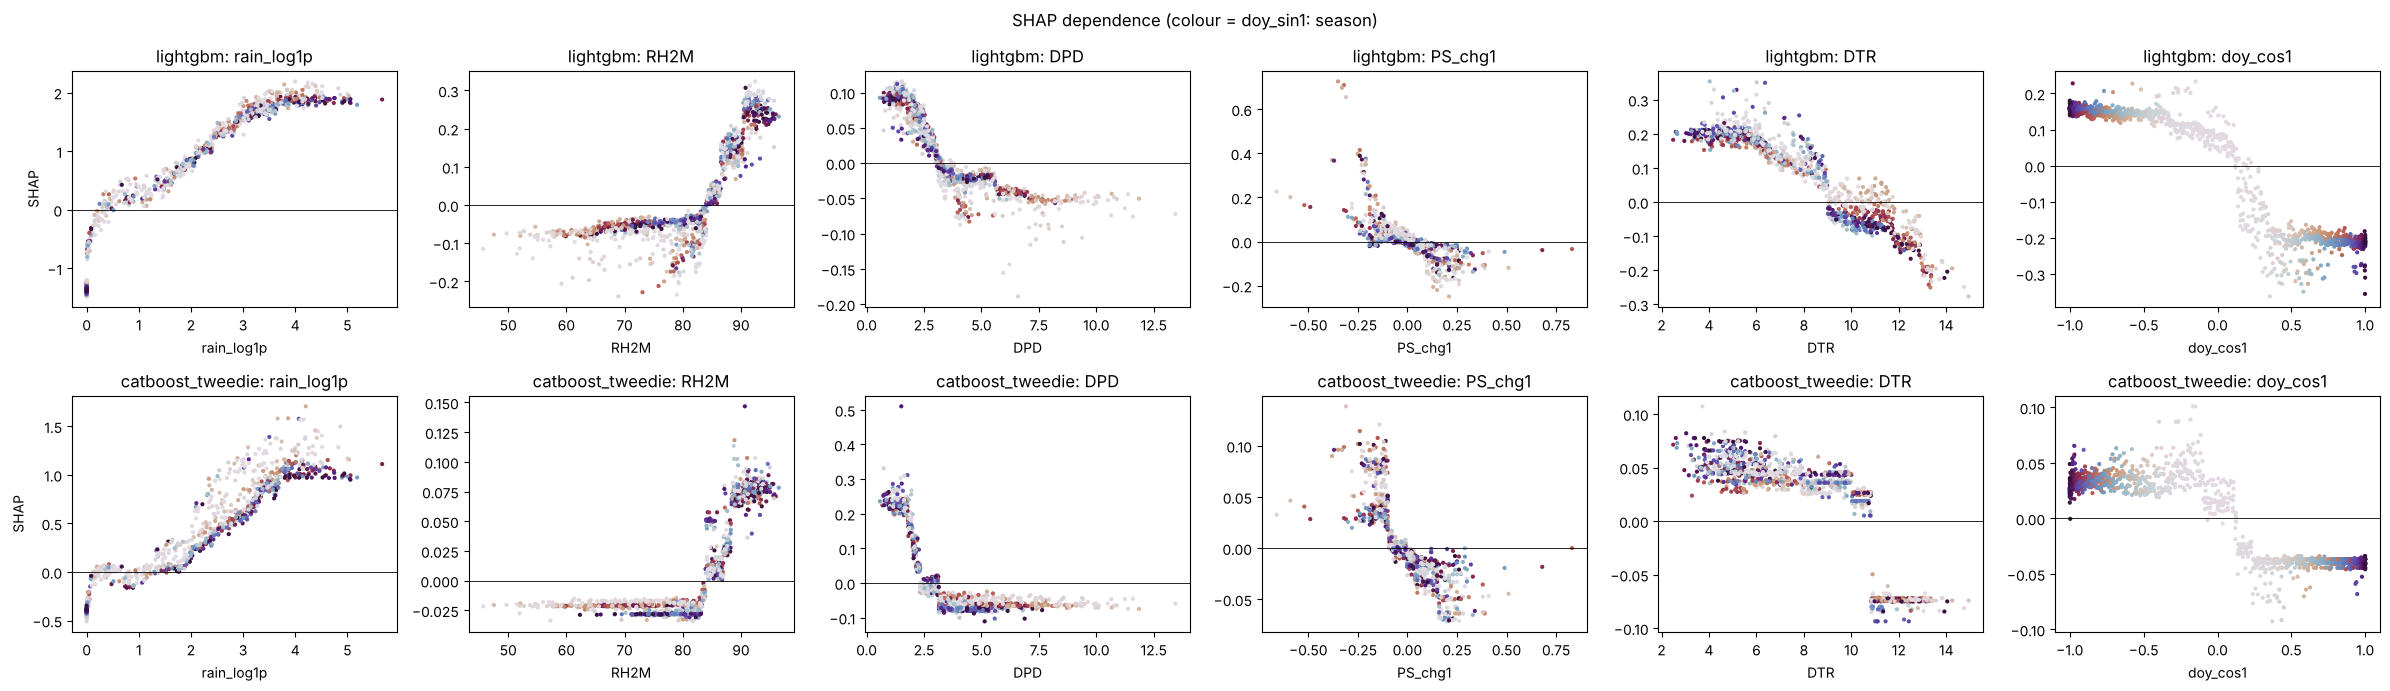

,lightgbm,catboost_tweedie
moisture,0.173,0.214
pressure,0.077,0.047
rain memory,0.424,0.400
season,0.076,0.061
temperature,0.201,0.216
wind,0.049,0.062


,lightgbm,catboost_tweedie
rain_log1p,1.274,0.530
T2M_MIN,0.279,0.051
PS,0.187,0.029
doy_cos1,0.166,0.037
wet_today,0.141,0.188
DTR,0.129,0.049
T2MDEW,0.126,0.029
doy_sin1,0.115,0.054
wet_run_len,0.113,0.071
QV2M,0.107,0.037


In [9]:
import shap
tr5, va5 = folds[4]
Xv = Xd.loc[va5]
expl = {}
for name in ("lightgbm", "catboost_tweedie"):
    sv = shap.TreeExplainer(models5[(name, 0)]).shap_values(Xv)
    sv = sv[1] if isinstance(sv, list) else sv
    expl[name] = pd.DataFrame(sv, index=Xv.index, columns=Xv.columns)
fig = plt.figure(figsize=(16, 7))
for j, name in enumerate(expl):
    ax = fig.add_subplot(1, 2, j + 1); plt.sca(ax)
    shap.summary_plot(expl[name].to_numpy(), Xv, max_display=15, show=False, plot_size=None)
    ax.set_title(f"{name} (fold 5, 2017-2019): SHAP " + ("log-odds" if name == "lightgbm" else "log-link"))
fig.tight_layout(); save(fig, "08_shap_beeswarm.png"); plt.show()
mabs = pd.DataFrame({n: e.abs().mean() for n, e in expl.items()})
grp = mabs.groupby(I.variable_group).sum()
mabs.to_csv(TAB / "08_shap_mean_abs.csv"); grp.to_csv(TAB / "08_shap_by_variable_group.csv")
DEP = ["rain_log1p", "RH2M", "DPD", "PS_chg1", "DTR", "doy_cos1"]
fig, axes = plt.subplots(2, 6, figsize=(24, 7))
for i, name in enumerate(expl):
    for j, f in enumerate(DEP):
        axes[i, j].scatter(Xv[f], expl[name][f], s=4, c=Xv["doy_sin1"], cmap="twilight")
        axes[i, j].axhline(0, color="k", lw=0.6); axes[i, j].set(xlabel=f, ylabel="SHAP" if j == 0 else None,
                                                                 title=f"{name}: {f}")
fig.suptitle("SHAP dependence (colour = doy_sin1: season)"); fig.tight_layout(); save(fig, "08_shap_dependence.png"); plt.show()
display((grp / grp.sum()).round(3)); display(mabs.sort_values("lightgbm", ascending=False).head(12).round(4))

**Interpretation (SHAP, fold-5 models on 2017–2019):**
- **Group shares of mean |SHAP|:**
  - LightGBM: rain memory 42 %, temperature 20 %, moisture 17 %, pressure 8 %, season 8 %, wind 5 %.
  - Tweedie: 40 / 22 / 21 / 5 / 6 / 6 %.
- **Top columns (LightGBM):** `rain_log1p` (1.27 log-odds), `T2M_MIN`, `PS`, `doy_cos1`, `wet_today`, `DTR`, `T2MDEW`.
- **Dependence plots (physically coherent):**
  - **Rain today:** contribution rises steeply from −1.4 (dry) to ≈ +2 log-odds and saturates beyond ≈ 20 mm (log1p ≈ 3). Persistence of the
    monsoon/convective regime.
  - **RH2M:** flat below ≈ 83 %, then a sharp rise of ≈ 0.3 log-odds above 85–90 %. Near-saturated boundary layer.
  - **Dew-point depression:** positive below ≈ 2.5 K and negative above ≈ 3 K. The same saturation signal, mirrored.
  - **PS tendency:** falling pressure (−0.25 to −0.5 kPa/day) raises the rain log-odds by up to +0.4 to +0.7; rising pressure lowers it.
    An approaching low or trough.
  - **DTR:** small diurnal range (< 7 K, cloudy, humid) gives +0.2; large range (> 11 K, clear skies) gives −0.2 to −0.3.
  - **Season:** `doy_cos1` near −1 (summer half-year) gives +0.15.
- The colour (season) shows that the humidity effects mostly apply in the transition and monsoon months.

**Paper note:** *SHAP analysis showed physically consistent effects: rain probability increased with same-day rainfall, near-saturated
humidity (RH > 85 %, dew-point depression < 3 K), falling surface pressure and a small diurnal temperature range.*

### Step 10 — Standardised coefficients of the best linear models across folds

**WHAT:** `logreg_l1` (tuned C ≈ 0.013) and `lasso` (tuned α ≈ 0.20) refitted per fold (Step 8 fits are reused for fold 5; here all 5
folds): coefficients on the standardised inputs (one-hot month columns are 0/1), mean ± std across folds and the number of folds in which
each column is selected (non-zero) with the same sign.

**WHY:** coefficients are directly comparable (per standard deviation of the input); sign stability across folds tells which effects are
robust. Strong collinearity makes individual magnitudes unreliable (Decision 4.8) — the *set* of selected variables is more informative.

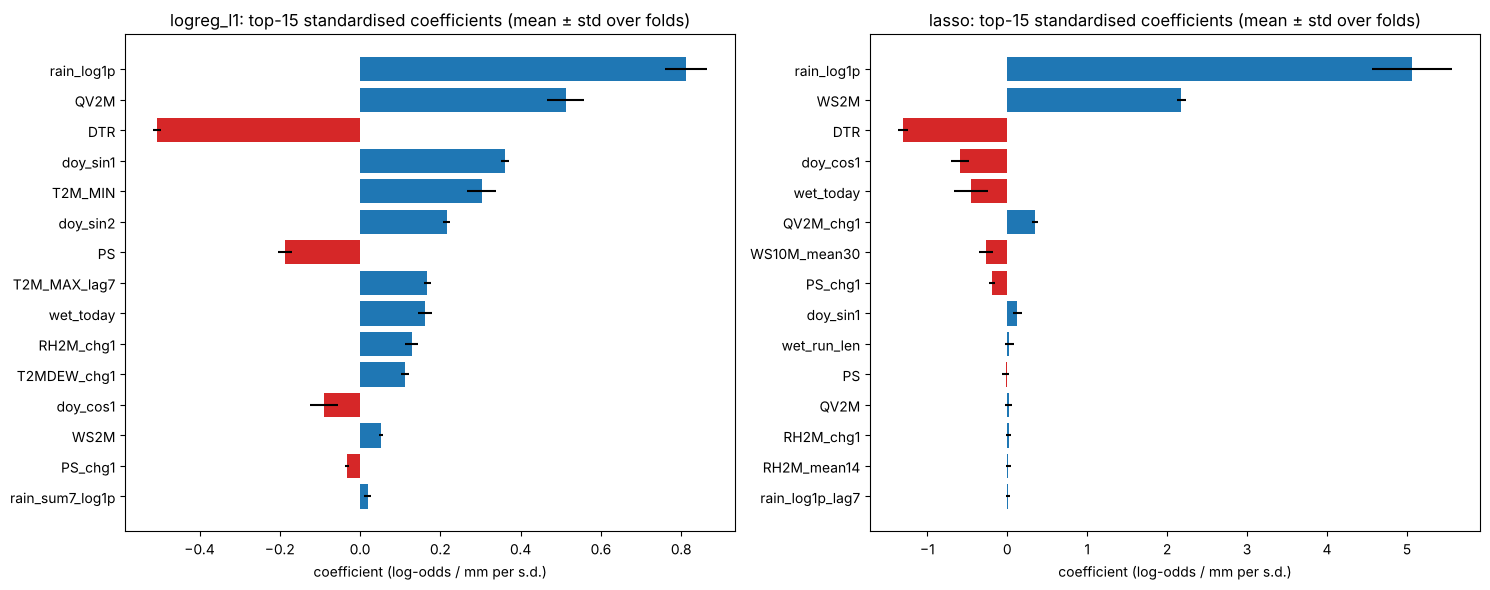

logreg_l1 columns selected in all 5 folds: 15 | ever selected: 16
lasso columns selected in all 5 folds: 9 | ever selected: 20


,model,feature,mean,std,folds_selected,folds_same_sign,abs_mean
113,lasso,rain_log1p,5.065,0.502,5,5,5.065
87,lasso,WS2M,2.176,0.058,5,5,2.176
1,lasso,DTR,-1.306,0.064,5,5,1.306
98,lasso,doy_cos1,-0.592,0.111,5,5,0.592
124,lasso,wet_today,-0.451,0.213,5,5,0.451
14,lasso,QV2M_chg1,0.345,0.042,5,5,0.345
85,lasso,WS10M_mean30,-0.272,0.088,5,5,0.272
3,lasso,PS_chg1,-0.190,0.032,5,5,0.190
100,lasso,doy_sin1,0.127,0.058,5,5,0.127
123,lasso,wet_run_len,0.025,0.055,1,1,0.025


In [10]:
coef_rows = []
for task, name in (("cls", "logreg_l1"), ("reg", "lasso")):
    y = Yd[E.TARGET[task]]
    for k, (tr, va) in enumerate(folds, 1):
        est = I.fold_model(task, name, 0, Xd, y, tr)
        lin = est[-1]
        names = est[0].get_feature_names_out()
        coef = np.ravel(lin.coef_)
        coef_rows.append(pd.DataFrame({"model": name, "fold": k, "feature": [n.split("__")[-1] for n in names], "coef": coef}))
coefs = pd.concat(coef_rows)
cs = coefs.groupby(["model", "feature"]).coef.agg(["mean", "std", lambda c: int((c != 0).sum()),
                                                   lambda c: int(max((c > 0).sum(), (c < 0).sum()))])
cs.columns = ["mean", "std", "folds_selected", "folds_same_sign"]
cs = cs.reset_index(); cs.to_csv(TAB / "08_linear_coefficients_folds.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, name in zip(axes, ("logreg_l1", "lasso")):
    c = cs[cs.model == name].reindex(cs[cs.model == name]["mean"].abs().sort_values(ascending=False).index).head(15)[::-1]
    ax.barh(c.feature, c["mean"], xerr=c["std"], color=np.where(c["mean"] > 0, "tab:blue", "tab:red"))
    ax.set(title=f"{name}: top-15 standardised coefficients (mean ± std over folds)", xlabel="coefficient (log-odds / mm per s.d.)")
fig.tight_layout(); save(fig, "08_linear_coefficients.png"); plt.show()
for name in ("logreg_l1", "lasso"):
    c = cs[cs.model == name]
    print(name, "columns selected in all 5 folds:", int((c.folds_selected == 5).sum()), "| ever selected:", int((c.folds_selected > 0).sum()))
sel = cs[cs.folds_selected > 0].assign(abs_mean=lambda d: d["mean"].abs())
sel.sort_values("abs_mean", ascending=False).groupby("model").head(12).sort_values(["model", "abs_mean"], ascending=[True, False]).round(3)

**Interpretation (standardised coefficients, 5 folds):**
- **logreg_l1 (C ≈ 0.013)** keeps **15 columns in all 5 folds**, all with a stable sign:
  - `rain_log1p` +0.81 log-odds per s.d., **QV2M +0.51**, **DTR −0.51**, `doy_sin1` +0.36, `T2M_MIN` +0.30, `doy_sin2` +0.22, **PS −0.19**,
    `T2M_MAX_lag7` +0.17, `wet_today` +0.16, `RH2M_chg1` +0.13, `T2MDEW_chg1` +0.11.
  - Moisture up, rising humidity, cloudy (small DTR), low pressure and today's rain all raise the rain probability: the same story as SHAP,
    in a transparent model.
- **lasso (α ≈ 0.20)** keeps **9 columns in all folds**: `rain_log1p` +5.1 mm per s.d., **WS2M +2.2 mm**, DTR −1.3, `doy_cos1` −0.6,
  `wet_today` −0.45, `QV2M_chg1` +0.35, `WS10M_mean30` −0.27, PS_chg1 −0.19.
  - The positive wind term reflects the stronger monsoon south-westerlies on very wet days.
  - The negative `wet_today` term is a correction, because `rain_log1p` already counts the wet day.
- Signs are stable across folds, but individual magnitudes are not interpretable in isolation (collinearity; Decision 4.8).

**Paper note:** *The sparse L1-regularised logistic model retained 15 predictors in every fold, with stable signs consistent with the
tree-model explanations (positive effects of rainfall, specific humidity and minimum temperature; negative effects of diurnal
temperature range and surface pressure).*

### Step 11 — Accumulated local effects (and PDP) for the main physical predictors

**WHAT:** first-order **ALE** (Apley & Zhu) for `rain_log1p`, `RH2M`, `DPD`, `PS_chg1` and `DTR` from the fold-5 LightGBM classifier
(P(wet), seed 0) and CatBoost Tweedie (mm) on the 2017–2019 validation rows; for comparison the classical **partial dependence**
(sklearn, brute force) of the classifier.

**WHY ALE:** PDP sets a feature to every value for *all* rows — e.g. RH2M = 40 % together with a dew-point depression of 1 K, an
impossible state — so with correlated inputs it extrapolates. ALE only moves each day within its own narrow bin and accumulates local
differences, which stays on the data manifold. **Look for:** agreement in shape, and where PDP and ALE diverge (a sign of collinearity).

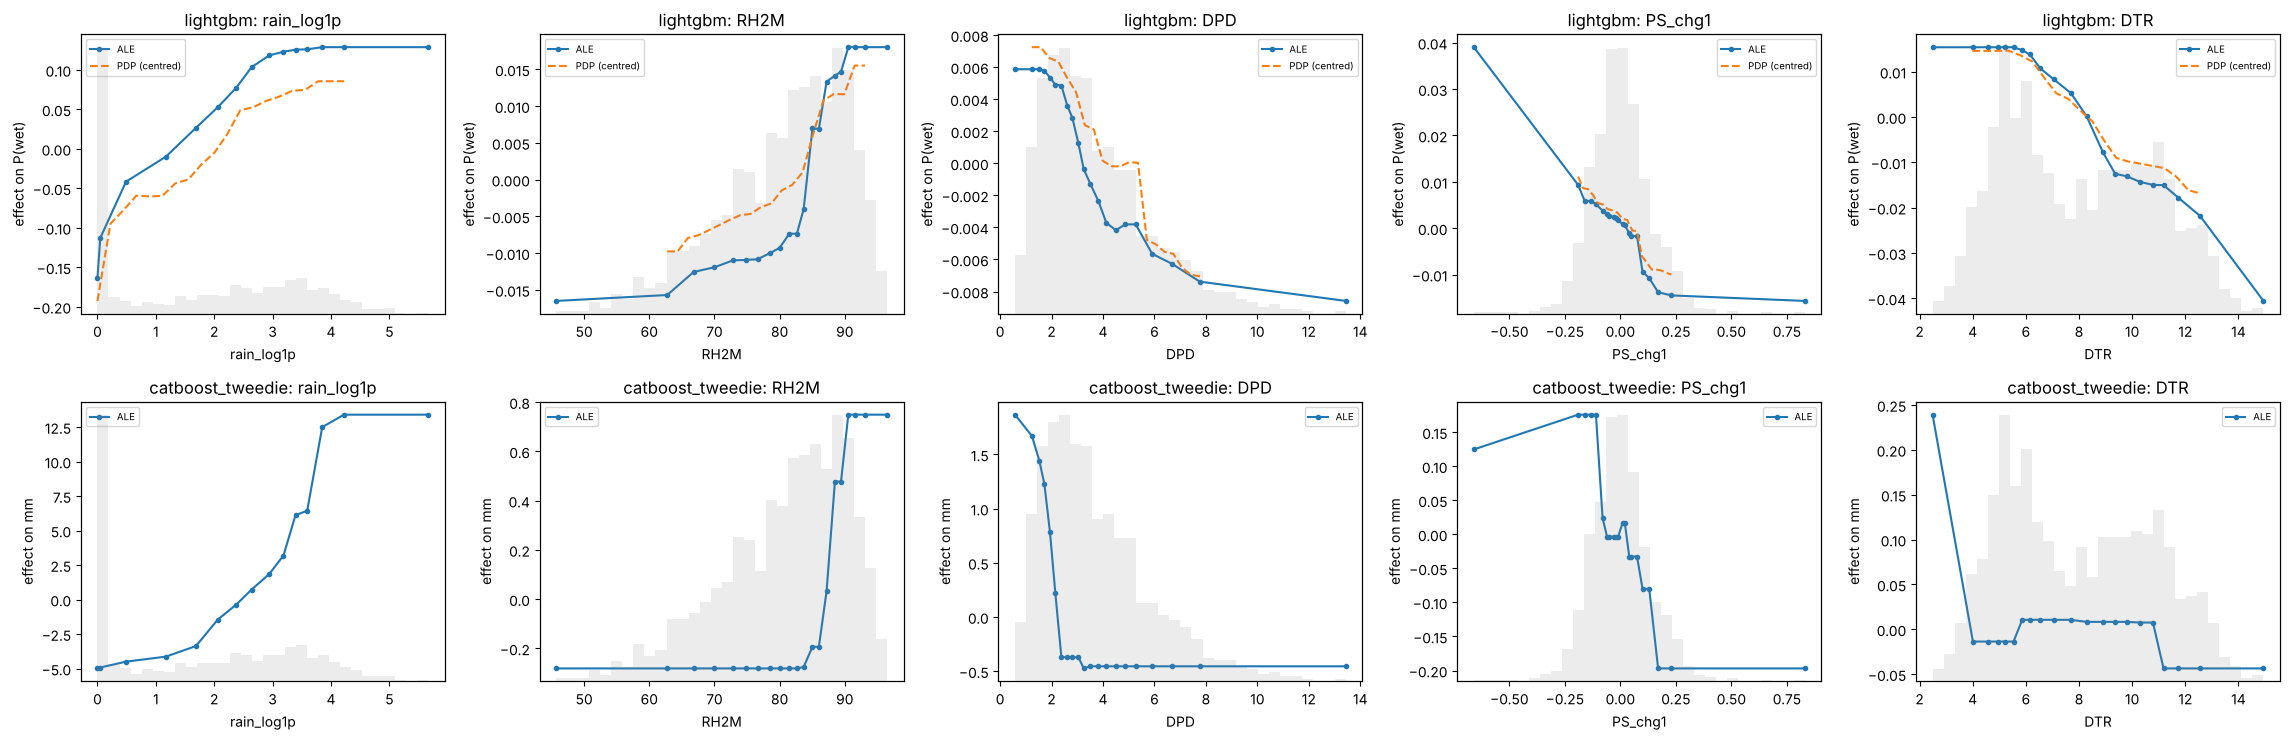

feature,DPD,DTR,PS_chg1,RH2M,rain_log1p
model,,,,,
catboost_tweedie,2.341,0.283,0.373,1.030,18.383
lightgbm,0.014,0.056,0.055,0.035,0.292


In [11]:
from sklearn.inspection import partial_dependence
FEATS = ["rain_log1p", "RH2M", "DPD", "PS_chg1", "DTR"]
fig, axes = plt.subplots(2, 5, figsize=(23, 7.5))
ale_rows = []
for i, (name, task) in enumerate((("lightgbm", "cls"), ("catboost_tweedie", "reg"))):
    est = models5[(name, 0)]
    for j, f in enumerate(FEATS):
        a = I.ale(est, Xv, f, task)
        ale_rows.append(a.assign(model=name, feature=f))
        axes[i, j].plot(a.x, a.ale, marker=".", label="ALE")
        if task == "cls":
            pdp = partial_dependence(est, Xv, [f], kind="average", grid_resolution=20, method="brute", response_method="predict_proba")
            axes[i, j].plot(pdp["grid_values"][0], pdp["average"][0] - pdp["average"][0].mean(), ls="--", label="PDP (centred)")
        axes[i, j].set(xlabel=f, ylabel="effect on P(wet)" if task == "cls" else "effect on mm", title=f"{name}: {f}")
        axes[i, j].legend(fontsize=7)
        ax2 = axes[i, j].twinx(); ax2.hist(Xv[f], bins=30, alpha=0.15, color="grey"); ax2.set_yticks([])
fig.tight_layout(); save(fig, "08_ale_pdp.png"); plt.show()
ale_tab = pd.concat(ale_rows); ale_tab.to_csv(TAB / "08_ale.csv", index=False)
ale_tab.groupby(["model", "feature"]).ale.agg(lambda a: a.max() - a.min()).rename("ALE range").unstack().round(3)

**Interpretation (ALE; PDP for comparison):**
- **LightGBM P(wet):**
  - Rain today has the largest effect: an ALE range of 0.29 in probability, saturating at ≈ 20 mm.
  - Then PS tendency (0.055) and DTR (0.056).
  - RH2M (0.035, almost all of it above 85 %) and DPD (0.014) are smaller, because their information is shared with QV2M/T2MDEW (ALE shows
    each feature's *own* contribution).
- **Tweedie (mm):** rain today 18 mm range, then **DPD 2.3 mm** (amount jumps when DPD < 2 K), RH 1.0 mm (above 88 %), PS tendency 0.4 mm,
  DTR 0.3 mm.
- **PDP vs ALE:** they agree in shape for the classifier. PDP is flatter for `rain_log1p` and shifted for RH2M, because PDP averages over
  impossible combinations (e.g. 0 mm today with a near-saturated humidity profile). The direction of every effect is the same.

**Paper note:** *Accumulated local effects confirmed monotone, threshold-like responses: rain probability and amount increased sharply
for relative humidity above ≈ 85 % or dew-point depression below ≈ 2–3 K, with falling surface pressure and a reduced diurnal
temperature range.*

### Step 12 — TFT variable selection and attention, consolidated with the other families

**WHAT:** the Stage-5 TFT encoder variable-selection weights (5 seeds, DL split, `05_tft_encoder_importance.csv`; Decision 5.11) mapped
onto the same physical groups, next to the LightGBM SHAP share, LightGBM / Tweedie grouped permutation importance and the share of
non-zero `logreg_l1` coefficients. TFT attention (Stage 5, figure `05_tft_explainability.png`) concentrated on days t and t−1.

**WHY:** if three very different model families point to the same physical drivers, the conclusion is more credible than any single
importance method. **Caveat:** each number measures something different (gate weight, attribution, loss increase, selection), so only
rankings are compared. The TFT VSN treats the raw rain series as the *target* input (its own lagged values), not as a covariate.

In [12]:
tft = pd.read_csv(TAB / "05_tft_encoder_importance.csv", index_col=0)
def tft_group(name):
    v = name.rsplit("_", 1)[0]
    return "rain memory" if v == "PRECTOTCORR" else I.variable_group(v)
tg = tft.encoder_mean.groupby(tft.index.map(tft_group)).sum()
pg = agg[agg.kind == "variable"].pivot(index="group", columns="model", values="mean")
lin_sel = cs[(cs.model == "logreg_l1") & (cs.folds_selected == 5)]
lin_g = lin_sel.assign(g=[I.variable_group(f) if not f.startswith("month") else "season" for f in lin_sel.feature]) \
    .groupby("g").feature.count()
comp = pd.DataFrame({"TFT VSN weight (%)": tg / tg.sum() * 100,
                     "LightGBM SHAP share (%)": grp["lightgbm"] / grp["lightgbm"].sum() * 100,
                     "LightGBM perm. ΔBrier share (%)": pg["lightgbm"].clip(lower=0) / pg["lightgbm"].clip(lower=0).sum() * 100,
                     "Tweedie perm. ΔMAE share (%)": pg["catboost_tweedie"].clip(lower=0) / pg["catboost_tweedie"].clip(lower=0).sum() * 100,
                     "logreg_l1 columns kept (5/5 folds)": lin_g}).fillna(0)
comp.round(1).to_csv(TAB / "08_importance_consolidated.csv")
ranks = comp.rank(ascending=False)
print("Spearman rank agreement between methods:"); display(comp.corr(method="spearman").round(2))
comp.round(1)

Spearman rank agreement between methods:


,TFT VSN weight (%),LightGBM SHAP share (%),LightGBM perm. ΔBrier share (%),Tweedie perm. ΔMAE share (%),logreg_l1 columns kept (5/5 folds)
TFT VSN weight (%),1.00,-0.26,-0.09,-0.49,0.44
LightGBM SHAP share (%),-0.26,1.00,0.94,0.77,0.68
LightGBM perm. ΔBrier share (%),-0.09,0.94,1.00,0.71,0.85
Tweedie perm. ΔMAE share (%),-0.49,0.77,0.71,1.00,0.37
logreg_l1 columns kept (5/5 folds),0.44,0.68,0.85,0.37,1.00


,TFT VSN weight (%),LightGBM SHAP share (%),LightGBM perm. ΔBrier share (%),Tweedie perm. ΔMAE share (%),logreg_l1 columns kept (5/5 folds)
moisture,38.2,17.3,12.5,13.4,3
pressure,4.7,7.7,1.5,2.4,2
rain memory,1.0,42.4,55.4,66.4,3
season,40.9,7.6,2.8,2.4,3
temperature,11.4,20.1,27.1,11.1,3
wind,3.8,4.9,0.7,4.4,1


**Interpretation (consolidation across families):**
- **The tree models and the linear model agree:** Spearman 0.68–0.94 among LightGBM SHAP, LightGBM permutation and logreg_l1 selection.
  Tweedie permutation is also similar (0.37–0.77). The order is rain memory ≫ temperature range ≈ moisture > season ≈ pressure > wind.
- **TFT ranks differently** (Spearman −0.49 to 0.44): its variable-selection network puts **season (41 %) and moisture (38 %, QV2M and
  RH2M)** first and gives the rain series only 1 %.
  - This is not a contradiction. In TFT the rain history is the *target* series, which feeds the LSTM directly, and the VSN only weighs the
    covariates.
  - Its attention focuses on days t and t−1 (Stage 5), i.e. on persistence.
- What remains robust across all three families is a **moist, low-DTR state plus recent rain**, modulated by season.

**Paper note:** *Across boosted trees, sparse logistic regression and the Temporal Fusion Transformer, humidity and the seasonal
cycle were consistently selected, while the tree and linear models additionally relied most on same-day rainfall.*

# Part 3 — Prompt 8.3: limitations and failure conditions

### Step 13 — Quantify the failure conditions used in the limitations table

**WHAT:** the numbers behind each limitation, computed here or read from earlier tables: the IMERG drop (Stage 6 ablation and Stage 7
secondary check), the PRECTOTCORR step changes, seasonal class imbalance at 0.1/1.0 mm, extreme-event under-prediction and the one-day lag
(cross-correlation of forecast and observation at lag 0 vs lag 1 on heavy days), and model size vs sample size.

In [13]:
ev = {}
# 1. reanalysis self-consistency
im7 = pd.read_csv(TAB / "07_imerg_secondary_cls.csv", header=[0, 1], index_col=0)
ev["test BSS LightGBM (PRECTOTCORR / IMERG)"] = (im7.loc["lightgbm", ("vs PRECTOTCORR", "BSS")], im7.loc["lightgbm", ("vs IMERG", "BSS")])
abl = pd.read_csv(TAB / "06_ablation_summary.csv")
ev["dev BSS LightGBM, 1998+ training (PRECTOTCORR / IMERG-trained)"] = tuple(
    abl[(abl.model == "lightgbm") & abl.variant.isin(["win_1998", "imerg_1998"])].set_index("variant").loc[["win_1998", "imerg_1998"], "BSS"].round(3))
# 3. inhomogeneity
raw = pd.read_parquet(ROOT / "data/processed/clean_daily.parquet")
tot = raw["PRECTOTCORR"].groupby(raw.index.year).sum()
ev["mean annual PRECTOTCORR 1981-97 / 1998-2015 / 2016-2025 (mm)"] = tuple(round(tot.loc[a:b].mean()) for a, b in ((1981, 1997), (1998, 2015), (2016, 2025)))
# 4. class imbalance by season (development and test)
d = Yd.join(Xd[["month"]]); d["season"] = FR.season_of(d.index).to_numpy()
ev["monsoon wet share dev 0.1 mm / 1 mm"] = tuple(d[d.season == "monsoon"][["y_cls_01", "y_cls"]].mean().round(3))
ev["winter wet share dev 0.1 mm / 1 mm"] = tuple(d[d.season == "winter"][["y_cls_01", "y_cls"]].mean().round(3))
ev["monsoon / winter wet share test (1 mm)"] = (round(y_cls[season == "monsoon"].mean(), 3), round(y_cls[season == "winter"].mean(), 3))
# 5. extremes and lag
heavy = (y_reg >= 50).to_numpy()
for mdl in ("catboost_tweedie", "hurdle_catboost_log_msess"):
    f = pd.Series(pr[mdl], index=tdate)
    nxt = f.shift(-1).to_numpy()
    ev[f"{mdl}: mean forecast on >=50 mm days (same day / next day) vs observed mean"] = (
        round(f[heavy].mean(), 1), round(np.nanmean(nxt[heavy]), 1), round(y_reg[heavy].mean(), 1))
    ev[f"{mdl}: corr(forecast, obs) lag 0 / forecast vs previous-day obs"] = (
        round(np.corrcoef(f, y_reg)[0, 1], 3), round(np.corrcoef(f.to_numpy()[1:], y_reg.to_numpy()[:-1])[0, 1], 3))
ev["test days >= 50 mm"] = int(heavy.sum())
# 6. sample size vs parameters
dt = pd.read_csv(TAB / "06_deep_tuning_budget.csv")
ev["development days / max deep parameters (tuned TFT-cls)"] = (len(Xd), int(dt["n_params best"].max()))
ev["features / training days per feature (Set B)"] = (Xd.shape[1], round(len(Xd) / Xd.shape[1]))
clean = lambda v: tuple(round(float(x), 3) for x in v) if isinstance(v, tuple) else v
evidence = pd.Series({k: str(clean(v)) for k, v in ev.items()}, name="value").to_frame()
evidence.to_csv(TAB / "08_limitations_evidence.csv"); evidence

,value
test BSS LightGBM (PRECTOTCORR / IMERG),"(0.368, -0.003)"
"dev BSS LightGBM, 1998+ training (PRECTOTCORR / IMERG-trained)","(0.259, 0.158)"
mean annual PRECTOTCORR 1981-97 / 1998-2015 / 2016-2025 (mm),"(1925.0, 2970.0, 5377.0)"
monsoon wet share dev 0.1 mm / 1 mm,"(0.962, 0.882)"
winter wet share dev 0.1 mm / 1 mm,"(0.14, 0.073)"
monsoon / winter wet share test (1 mm),"(0.958, 0.077)"
catboost_tweedie: mean forecast on >=50 mm days (same day / next day) vs observed mean,"(37.0, 45.1, 83.3)"
"catboost_tweedie: corr(forecast, obs) lag 0 / forecast vs previous-day obs","(0.712, 0.873)"
hurdle_catboost_log_msess: mean forecast on >=50 mm days (same day / next day) vs observed mean,"(51.6, 63.6, 83.3)"
"hurdle_catboost_log_msess: corr(forecast, obs) lag 0 / forecast vs previous-day obs","(0.699, 0.869)"


**Interpretation:** these numbers feed the limitations table below. The decisive ones:
- the BSS against IMERG (−0.003 on test, vs 0.368 against PRECTOTCORR);
- the tripling of mean annual PRECTOTCORR across the record (1,925 → 5,377 mm);
- the one-day lag on heavy days. Forecasts are **larger on the day *after*** a ≥ 50 mm day than on the day itself (Tweedie 37 → 45 mm,
  hurdle 52 → 64 mm, against 83 mm observed). The forecast also correlates better with the *previous* day's observation (0.87) than with
  the target day (0.71);
- the parameter-to-sample ratio of the deep models (413 k parameters vs 14 k days).

**Paper note:** *Forecasts on heavy-rain days correlated more strongly with the preceding day's observed rainfall (r = 0.87) than with the
verifying day (r = 0.71), quantifying the persistence-driven one-day lag.*

### Step 14 — Limitations and failure conditions (for the paper)

The table below (also `reports/tables/08_limitations_summary.csv` and `reports/08_limitations.md`) lists each limitation with
(a) our evidence, (b) its effect on the conclusions and (c) the future work that would address it.

**Prose for the paper (draft).** Our results characterise how well machine-learning models forecast **next-day MERRA-2 PRECTOTCORR
rainfall** for one 0.5° × 0.625° grid cell over Sylhet, not observed rainfall:
- **The reanalysis caveat is the largest.** Scored against independent IMERG precipitation, the same frozen forecasts keep their
  discrimination (ROC-AUC ≈ 0.92) but lose almost all Brier skill (BSS ≈ 0). A model trained on IMERG reaches about 60 % of the
  PRECTOTCORR skill (BSS 0.16 vs 0.26). Part of the skill therefore reflects the internal consistency of reanalysis predictors and
  reanalysis rainfall.
- **The rainfall product is inhomogeneous**: mean annual totals rose from ≈ 1,900 to ≈ 5,400 mm across the record while IMERG was flat.
  This produced a wetter test period, inflated skill relative to climatology and under-forecasting biases.
- **Single-cell surface predictors** limit the models to persistence and local thermodynamic state. Onsets of rain are partly anticipated,
  but heavy events are damped to 30–60 % of their observed amount and lag by a day. The models therefore cannot serve as flood early-warning
  tools.
- **The deep models were limited by sample size** rather than by architecture.
- **Because inputs are day-t reanalysis fields with publication latency and no NWP guidance**, the study is a diagnostic hindcast
  benchmark, not an operational system.

Rankings of model families were stable across thresholds, rainfall sources and periods, so the comparative conclusions are more robust
than the absolute skill values.

In [14]:
LIMITS = [
    ("1. Reanalysis rainfall (MERRA-2 PRECTOTCORR, 0.5° × 0.625° grid cell) instead of BMD rain-gauge data",
     "Against independent IMERG: dev LightGBM BSS 0.259 (PRECTOTCORR, 1998+ training) vs 0.158 when trained and scored on IMERG; on the test "
     "years the frozen forecasts reach BSS 0.368 vs PRECTOTCORR but -0.003 vs IMERG (ROC-AUC 0.97 vs 0.92); MSESS 0.39-0.42 vs 0.11-0.18. "
     "Predictors and target come from the same reanalysis (self-consistency).",
     "Headline skill measures the ability to forecast MERRA-2 rainfall; skill against observed rain is much smaller and mostly in "
     "discrimination, not calibration. Model rankings are robust; absolute numbers are upper bounds.",
     "Verify against BMD Sylhet station gauges and IMERG-Final; train on observation-based targets or recalibrate on them (Platt/beta "
     "calibration, prior shift); report both."),
    ("2. Single grid cell (24.9157°N, 91.832°E), no spatial or upstream information",
     "All 115 predictors are local surface variables; skill is concentrated in rain memory (≈ 42 % of LightGBM SHAP, 55-70 % of grouped "
     "permutation importance); monsoon-month BSS of the learners only 0.09-0.34 and onsets caught 41-59 % at best.",
     "Models cannot see approaching systems (Bay of Bengal moisture surges, Meghalaya/Cherrapunji orographic inflow), so they rely on "
     "persistence and seasonal state; conclusions do not transfer to other sites without re-testing.",
     "Add neighbouring cells / upstream gradients (moisture flux, 850 hPa winds), ERA5 fields, multi-site or spatio-temporal models (ConvLSTM, GNN)."),
    ("3. Temporal inhomogeneity of PRECTOTCORR (step changes ≈ 2000 and ≈ 2016) and of MERRA-2 humidity",
     "Mean annual PRECTOTCORR 1,925 / 2,970 / 5,377 mm (1981-97 / 1998-2015 / 2016-25) while IMERG is flat (3,680 vs 3,757 mm); Pettitt "
     "change points p < 0.001 (Stage 1); test wet-day share 55.7 % vs 49.4 % in development.",
     "Part of the 'regime shift' is a product artefact; it inflates BSS vs climatology on test (+0.10 for all models), causes the "
     "MAE-type under-forecast bias (-1.8 to -4.5 mm/day) and the under-forecasting in reliability diagrams.",
     "Homogenisation or bias adjustment against gauges/IMERG; train on homogeneous products; report skill vs persistence-type references."),
    ("4. Seasonal class imbalance",
     "Rain-day share in development: monsoon 96.2 % (0.1 mm) / 88.2 % (1 mm), winter 14.0 % / 7.3 %; test monsoon 95.8 %, winter 7.7 % "
     "(1 mm). Only 31 rain-free monsoon days in 2020-2025; 12-16 per 3-year development fold at 0.1 mm.",
     "Within-season discrimination is estimated from very few events (monsoon ROC-AUC unstable, up to 0.97 at 0.1 mm); annual "
     "scores are dominated by the easy seasonal contrast; occurrence forecasts in the monsoon are nearly constant (P ≈ 0.95-1).",
     "Season-specific evaluation and models, thresholds relative to climatology (e.g. heavy-rain percentiles), more years/sites."),
    ("5. Under-prediction and one-day lag of heavy and extreme rain",
     "167 test days ≥ 50 mm (mean 83 mm): forecasts on those days 37 mm (Tweedie), 52 (hurdle), 48 (TiDE), 36 (seasonal+persistence), "
     "but 45 / 64 / 62 / 48 mm on the FOLLOWING day; corr(forecast, obs) 0.71 vs 0.87 with the previous day's observation; ≥ 50 mm recall "
     "0.22 (Tweedie) to 0.49 (hurdle); 99.9th-percentile forecasts 50-130 mm vs 190 mm observed.",
     "The models are not early-warning tools for flash floods (e.g. the June 2022 and June 2024 Sylhet events); they react after heavy rain.",
     "NWP or upstream inputs, quantile/extreme-value losses, event-based verification (e.g. SEDI), sub-daily data."),
    ("6. Sample-size ceiling for deep sequence models",
     "14,214 development days (≈ 39 monsoons) at one site; 115 features (124 days per feature); tuned TFT classifier 412,927 parameters; deep "
     "tuning did not transfer from the 2012-14 slice to 2015-19; one TSMixer seed early-stopped at epoch 1 (test MAE 13.2 mm).",
     "Deep models are data-limited and seed-sensitive; their failure to beat boosters is a statement about this data regime, "
     "not about the architectures in general.",
     "Pool many grid cells/stations, pre-training on large reanalysis archives, stronger regularisation, ensembles."),
    ("7. No NWP inputs; UTC day; data latency — a diagnostic hindcast, not an operational system",
     "Inputs are day-t reanalysis values only; POWER days are UTC (06:00-06:00 Bangladesh time), not a gauge reporting day (typically 24 h ending in the morning local time); "
     "MERRA-2-based POWER data are published with a delay of weeks, so day-t inputs are not available at the end of day t in real time.",
     "Skill is that of a perfect-information persistence-plus-state model; operational skill would be lower, and NWP-based forecasts "
     "(which see the incoming weather) are the relevant operational benchmark.",
     "Use real-time inputs (GFS/ECMWF analyses, near-real-time IMERG), add NWP day-1 forecasts as predictors, align to the gauge reporting day."),
    ("8. Non-stationarity and climate / product drift between training and evaluation decades",
     "All test MAEs +1.6 to +2.6 mm and BSS vs climatology +0.09 to +0.12 vs development; ranking stable (Spearman 0.88-0.95); shorter recent-only "
     "training windows did not help (win_2010 ΔBSS -0.06); deep tuning on 2012-14 did not transfer to 2015-19.",
     "Absolute scores depend on the period; relative conclusions are more robust. A model trained on 1981-2019 is already "
     "mis-calibrated for 2020-2025 (under-forecast probabilities and amounts).",
     "Rolling re-training and recalibration, drift monitoring, equal-length era ablations (separating sample size from regime)."),
    ("9. Single test period and selection effects",
     "One 6-year test window (2,192 days, 72 months as bootstrap blocks); tuned CV scores carry fold-selection optimism (seed-0 optimism "
     "≈ 0.003 BSS for boosters); about 84 ablation contrasts without multiplicity correction.",
     "Small differences between good models (≤ 0.01 BSS) are not resolvable; only Holm-significant test differences are claimed.",
     "Longer or additional independent test periods, more sites, nested CV."),
    ("10. Limits of interpretability methods",
     "Strong collinearity (lags, rolling means, humidity variables): single-column permutation importances are unstable while grouped ones "
     "are not; PDP and ALE agree in shape but differ in magnitude (e.g. rain_log1p); TFT gate weights rank variables differently from SHAP/permutation (Spearman -0.49 to 0.44).",
     "Importances describe the fitted models, not physical causation; only group-level statements that agree across methods are used.",
     "Causal or physically constrained designs, controlled experiments with NWP, conditional importance methods."),
]
lim = pd.DataFrame(LIMITS, columns=["limitation", "evidence (our numbers)", "effect on conclusions", "future work"])
lim.to_csv(TAB / "08_limitations_summary.csv", index=False)
md_lines = ["| # | Limitation | Evidence | Effect on conclusions | Future work |", "|---|---|---|---|---|"]
md_lines += [f"| {i} | {a} | {b} | {c} | {d} |" for i, (a, b, c, d) in enumerate(LIMITS, 1)]
(ROOT / "reports/08_limitations.md").write_text("# Limitations and failure conditions (Stage 8.3)\n\n" + "\n".join(md_lines) + "\n")
print("saved reports/tables/08_limitations_summary.csv and reports/08_limitations.md;", len(lim), "limitations")
lim

saved reports/tables/08_limitations_summary.csv and reports/08_limitations.md; 10 limitations


,limitation,evidence (our numbers),effect on conclusions,future work
0,"1. Reanalysis rainfall (MERRA-2 PRECTOTCORR, 0...",Against independent IMERG: dev LightGBM BSS 0....,Headline skill measures the ability to forecas...,Verify against BMD Sylhet station gauges and I...
1,"2. Single grid cell (24.9157°N, 91.832°E), no ...",All 115 predictors are local surface variables...,Models cannot see approaching systems (Bay of ...,Add neighbouring cells / upstream gradients (m...
2,3. Temporal inhomogeneity of PRECTOTCORR (step...,"Mean annual PRECTOTCORR 1,925 / 2,970 / 5,377 ...",Part of the 'regime shift' is a product artefa...,Homogenisation or bias adjustment against gaug...
3,4. Seasonal class imbalance,Rain-day share in development: monsoon 96.2 % ...,Within-season discrimination is estimated from...,"Season-specific evaluation and models, thresho..."
4,5. Under-prediction and one-day lag of heavy a...,167 test days ≥ 50 mm (mean 83 mm): forecasts ...,The models are not early-warning tools for fla...,"NWP or upstream inputs, quantile/extreme-value..."
5,6. Sample-size ceiling for deep sequence models,"14,214 development days (≈ 39 monsoons) at one...",Deep models are data-limited and seed-sensitiv...,"Pool many grid cells/stations, pre-training on..."
6,7. No NWP inputs; UTC day; data latency — a di...,Inputs are day-t reanalysis values only; POWER...,Skill is that of a perfect-information persist...,"Use real-time inputs (GFS/ECMWF analyses, near..."
7,8. Non-stationarity and climate / product drif...,All test MAEs +1.6 to +2.6 mm and BSS vs clima...,Absolute scores depend on the period; relative...,"Rolling re-training and recalibration, drift m..."
8,9. Single test period and selection effects,"One 6-year test window (2,192 days, 72 months ...",Small differences between good models (≤ 0.01 ...,"Longer or additional independent test periods,..."
9,10. Limits of interpretability methods,"Strong collinearity (lags, rolling means, humi...","Importances describe the fitted models, not ph...","Causal or physically constrained designs, cont..."


### SKEPTICAL-REVIEWER — Stage 8

| # | Criticism | Answer |
|---|---|---|
| 1 | *"Error analysis on the test set invites post-hoc tuning."* | It is descriptive only: no model, threshold or setting was changed (rule 4; frozen files untouched). |
| 2 | *"Importance computed on training data is optimistic."* | Permutation and SHAP use development validation folds (out-of-sample), never training rows or test days. |
| 3 | *"Your top features are collinear; rankings are artefacts."* | That is why the claims are group-level and cross-method (SHAP vs permutation Spearman 0.94). Single columns other than `rain_log1p` are not interpreted. |
| 4 | *"SHAP and ALE show association, not causation."* | Stated explicitly. The effects agree with known physics (saturation, pressure falls, cloudiness), which supports but does not prove a mechanism. |
| 5 | *"FN/FP 'synoptic states' are only local surface variables."* | Correct; we call them local states. Synoptic attribution would need upstream fields (limitation 2). |
| 6 | *"ENSO labels are approximate."* | Yes; labelled approximate, to be verified against the NOAA CPC ONI table. No ENSO claim is made from six years. |
| 7 | *"TFT importance disagrees with the boosters."* | Explained by architecture (the target history bypasses the VSN). Reported, not hidden. |
| 8 | *"Monthly/seasonal slices with few events are noisy."* | Day counts are given; no significance claims are made for slices. |

### Stage 8 — summary
1. **Where skill lives:** the transition months (BSS 0.41–0.49) and rain onsets (41–59 % caught, AUC 0.87–0.89 where persistence is always
   wrong); little skill in the core monsoon.
2. **Where it fails:**
   - heavy rain is damped to 32–62 % of the observed amount and lags by a day;
   - dry days get 1–3 mm of "drizzle";
   - misses are light winter and pre-monsoon rain from an apparently dry state;
   - cessations are rarely called.
3. **What the models use:** recent rain first, then a cloudy, near-saturated, low-pressure state (small DTR, RH > 85 %, DPD < 3 K, falling
   PS), modulated by season. Consistent across trees, linear models and, for moisture and season, TFT.
4. **Limitations:** ten, quantified; the reanalysis target and its inhomogeneity dominate.

Outputs: tables `08_*.csv` (errors by month / intensity / year, FN–FP states, transitions, calibration by season, permutation
importance, SHAP, linear coefficients, ALE, consolidated importance, limitations), `reports/08_limitations.md`; figures `08_*.png`.

---

## END-OF-STAGE 8 — five things you must be able to explain in the paper
1. **Where the models add value:** transition seasons and rain onsets (probabilities rise before onsets), not the core monsoon. Occurrence
   there is near-certain and only the amount is uncertain.
2. **How and why heavy rain is mis-forecast:** amount damping (32–62 %) and a one-day lag (forecast correlates 0.87 with yesterday's rain,
   0.71 with the target day). This follows from single-cell, persistence-dominated inputs.
3. **The physical drivers the models use,** and how we know: grouped permutation + SHAP + ALE + L1 coefficients on out-of-sample
   development folds, agreeing at group level (recent rain; saturation, RH > 85 % or DPD < 3 K; small DTR; falling pressure; season).
4. **Why importance is not causation,** and why group-level importances are reported (collinearity, method disagreement, TFT's
   architecture).
5. **The limits:** reanalysis self-consistency (IMERG), product inhomogeneity, single cell, no NWP or latency, sample size, non-stationarity.

## Check your understanding (3 questions)
1. On days with ≥ 50 mm, the Tweedie forecast is larger on the *following* day (45 mm) than on the day itself (37 mm). Which input causes
   this, and why can no model built only on day-t local variables avoid it?
2. Permuting the "current" family raises LightGBM's Brier score by 0.20, but permuting the "lag" family alone raises it by only 0.001.
   Does that mean lagged information is useless? Relate your answer to the Stage-6 drop-family ablation and to collinearity.
3. Missed rain days have almost the same local state as correctly forecast dry days (RH ≈ 74 %, DPD ≈ 5 K, DTR ≈ 11 K). What does that
   imply about the source of those rain events, and which additional data would you need to catch them?